# 🛒 GroceryIQ — Data Pre-processing & Feature Engineering

**Continuous Evaluation 1 (CE1) — Full Stack Engineering, University Coding Academy (CSE)**

---

## Project Overview

**GroceryIQ** is an AI-powered grocery store management platform that handles inventory, POS, and self-hosted ML analytics. This notebook demonstrates the complete **data pre-processing and feature engineering pipeline** using synthetic grocery store data.

### Syllabus Topics Covered

| # | Topic | Section |
|---|---|---|
| 1 | Google Colab & Python Libraries | Section 1 |
| 2 | Data Collection | Section 2 |
| 3 | Data Cleaning | Section 4 |
| 4 | Handling Missing Values | Section 5 |
| 5 | Data Integration | Section 6 |
| 6 | Data Transformation | Section 7 |
| 7 | Data Reduction | Section 8 |
| 8 | Feature Scaling (Normalization & Standardization) | Section 9 |
| 9 | Feature Engineering | Section 10 |
| 10 | Feature Selection | Section 11 |
| 11 | Feature Extraction | Section 12 |
| 12 | Preparation of Training & Testing Datasets | Section 13 |

---
## Section 1: Introduction to Google Colab & Python Libraries

Google Colab is a free, cloud-based Jupyter notebook environment that requires no setup. It provides access to GPUs, TPUs, and comes pre-installed with most data science libraries.

We will use the following essential Python libraries:

| Library | Purpose |
|---|---|
| **NumPy** | Numerical computing — arrays, linear algebra, random number generation |
| **Pandas** | Data manipulation — DataFrames, groupby, merge, pivot |
| **Matplotlib** | Data visualization — line plots, bar charts, histograms |
| **Seaborn** | Statistical visualization — heatmaps, pair plots, distribution plots |
| **Scikit-Learn** | Machine learning — preprocessing, feature selection, model building |

In [1]:
# ═══════════════════════════════════════════════════════════════
# Section 1: Import Essential Python Libraries
# ═══════════════════════════════════════════════════════════════

# Core data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules
from sklearn.preprocessing import (
    MinMaxScaler,         # Normalization (min-max scaling)
    StandardScaler,       # Standardization (z-score scaling)
    LabelEncoder,         # Label encoding for categorical variables
    OneHotEncoder,        # One-hot encoding for categorical variables
)
from sklearn.decomposition import PCA              # Principal Component Analysis
from sklearn.feature_selection import (
    SelectKBest,          # Feature selection
    mutual_info_regression,  # Mutual information scoring
    f_regression,         # F-statistic scoring
)
from sklearn.model_selection import train_test_split  # Train/test split
from sklearn.impute import SimpleImputer              # Missing value imputation

# Other utilities
import warnings
import os
import random
import uuid
from datetime import datetime, timedelta

# Configuration
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 20)
sns.set_theme(style='whitegrid', palette='husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print('\u2705 All libraries imported successfully!')
print(f'   NumPy version:        {np.__version__}')
print(f'   Pandas version:       {pd.__version__}')
print(f'   Matplotlib version:   {plt.matplotlib.__version__}')
print(f'   Seaborn version:      {sns.__version__}')
import sklearn
print(f'   Scikit-Learn version: {sklearn.__version__}')

✅ All libraries imported successfully!
   NumPy version:        2.5.1
   Pandas version:       3.0.5
   Matplotlib version:   3.11.1
   Seaborn version:      0.13.2
   Scikit-Learn version: 1.9.0


### Demonstrating NumPy

NumPy provides powerful N-dimensional array objects and mathematical operations.

In [2]:
# NumPy demonstration
print('=== NumPy Demonstration ===')

# Creating arrays
prices = np.array([299, 150, 450, 89, 199, 350, 120, 499])
quantities = np.array([10, 25, 5, 40, 15, 8, 30, 3])

print(f'Product prices (cents):    {prices}')
print(f'Quantities in stock:       {quantities}')
print(f'Revenue (price × qty):     {prices * quantities}')
print(f'Mean price:                {np.mean(prices):.2f} cents')
print(f'Std deviation of prices:   {np.std(prices):.2f} cents')
print(f'Total inventory value:     {np.sum(prices * quantities)} cents')

# Random number generation (useful for synthetic data)
daily_sales = np.random.poisson(lam=12, size=30)
print(f'\nSimulated 30-day sales (Poisson λ=12): {daily_sales}')

=== NumPy Demonstration ===
Product prices (cents):    [299 150 450  89 199 350 120 499]
Quantities in stock:       [10 25  5 40 15  8 30  3]
Revenue (price × qty):     [2990 3750 2250 3560 2985 2800 3600 1497]
Mean price:                269.50 cents
Std deviation of prices:   144.39 cents
Total inventory value:     23432 cents

Simulated 30-day sales (Poisson λ=12): [11 14  8 13 16  8 10 11 13 10 11  8 13 13 10 14  7  9 10 12  6  4 11 16
 10  8 15 14 15 10]


### Demonstrating Pandas

Pandas provides DataFrames — tabular data structures with powerful manipulation capabilities.

In [3]:
# Pandas demonstration
print('=== Pandas Demonstration ===')

demo_df = pd.DataFrame({
    'product': ['Milk', 'Bread', 'Eggs', 'Cheese', 'Butter'],
    'category': ['Dairy', 'Bakery', 'Dairy', 'Dairy', 'Dairy'],
    'price_cents': [299, 150, 350, 450, 200],
    'daily_sales': [45, 60, 30, 20, 35]
})

print('\nSample DataFrame:')
display(demo_df)

print('\nGroupBy — average daily sales by category:')
display(demo_df.groupby('category')['daily_sales'].mean())

print(f'\nTotal daily revenue: {(demo_df["price_cents"] * demo_df["daily_sales"]).sum()} cents')

=== Pandas Demonstration ===

Sample DataFrame:


,product,category,price_cents,daily_sales
0,Milk,Dairy,299,45
1,Bread,Bakery,150,60
2,Eggs,Dairy,350,30
3,Cheese,Dairy,450,20
4,Butter,Dairy,200,35



GroupBy — average daily sales by category:


category
Bakery    60.0
Dairy     32.5
Name: daily_sales, dtype: float64


Total daily revenue: 48955 cents


### Demonstrating Matplotlib & Seaborn

Visualization is essential for understanding data distributions, relationships, and patterns.

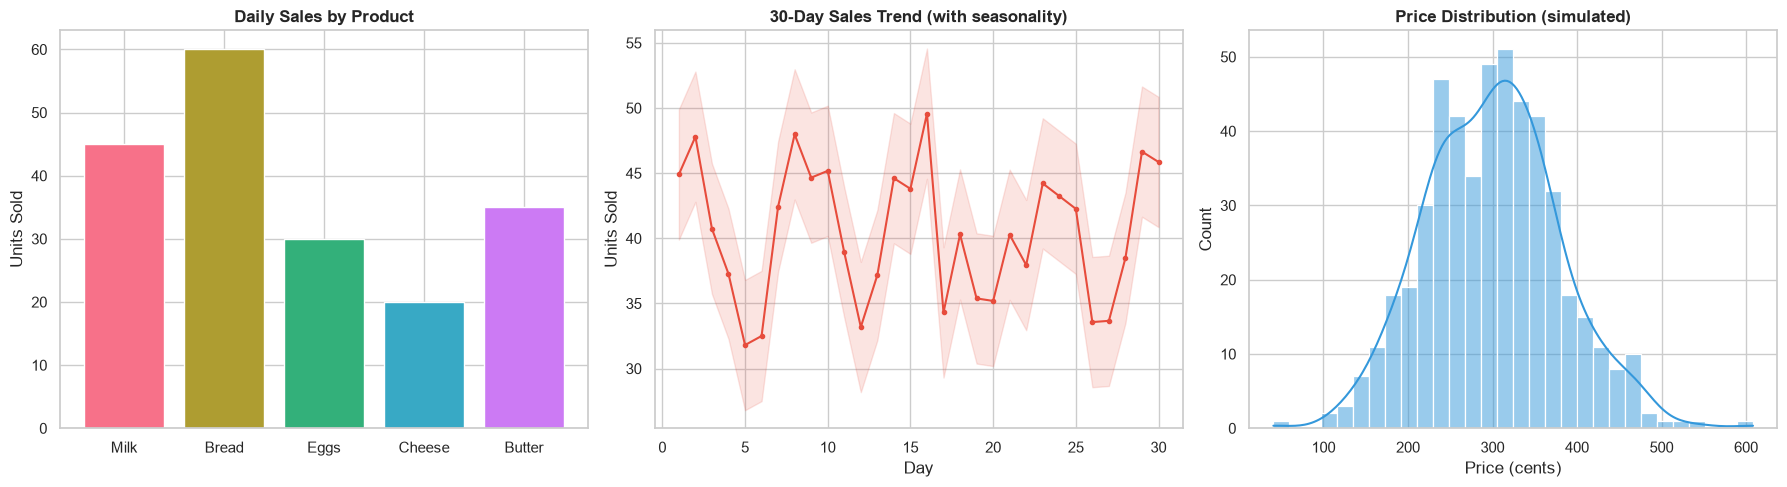

In [4]:
# Matplotlib & Seaborn demonstration
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bar chart
axes[0].bar(demo_df['product'], demo_df['daily_sales'], color=sns.color_palette('husl', 5))
axes[0].set_title('Daily Sales by Product', fontweight='bold')
axes[0].set_ylabel('Units Sold')

# Line plot (simulated 30-day trend)
days = np.arange(1, 31)
trend = 40 + 5 * np.sin(2 * np.pi * days / 7) + np.random.normal(0, 3, 30)
axes[1].plot(days, trend, marker='o', markersize=3, linewidth=1.5, color='#e74c3c')
axes[1].fill_between(days, trend - 5, trend + 5, alpha=0.15, color='#e74c3c')
axes[1].set_title('30-Day Sales Trend (with seasonality)', fontweight='bold')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Units Sold')

# Distribution
sns.histplot(np.random.normal(300, 80, 500), bins=30, kde=True, ax=axes[2], color='#3498db')
axes[2].set_title('Price Distribution (simulated)', fontweight='bold')
axes[2].set_xlabel('Price (cents)')

plt.tight_layout()
plt.show()

---
## Section 2: Data Collection

Data collection is the process of gathering raw data from various sources. In GroceryIQ, our data comes from:

1. **Products catalog** — SKU, name, category, pricing
2. **Transaction records** — POS sales data over 90 days
3. **Batch inventory** — batch tracking with expiry dates
4. **Stock movements** — stock changes (sales, restocking, shrinkage)

We generate synthetic data that mirrors a real grocery store's operational data.

In [5]:
# ═══════════════════════════════════════════════════════════════
# Section 2: Data Collection — Generate Synthetic Grocery Data
# ═══════════════════════════════════════════════════════════════

# Product catalogue for GroceryIQ
CATEGORIES = {
    'Dairy': ['Whole Milk 1L', 'Cheddar Cheese 200g', 'Greek Yogurt 500g',
              'Butter 250g', 'Cream Cheese 150g', 'Mozzarella 200g',
              'Skimmed Milk 1L', 'Paneer 200g'],
    'Produce': ['Bananas 1kg', 'Tomatoes 1kg', 'Spinach 200g', 'Apples 1kg',
                'Onions 1kg', 'Potatoes 2kg', 'Carrots 500g', 'Lemons 500g'],
    'Bakery': ['White Bread', 'Whole Wheat Bread', 'Croissants (4pk)',
               'Dinner Rolls (6pk)', 'Bagels (4pk)', 'Muffins (4pk)'],
    'Snacks': ['Potato Chips 150g', 'Salsa Dip 250g', 'Tortilla Chips 200g',
               'Chocolate Bar', 'Mixed Nuts 200g', 'Popcorn 100g',
               'Cookies 300g', 'Granola Bar (6pk)'],
    'Pantry': ['Rice 1kg', 'Pasta 500g', 'Cooking Oil 1L', 'Canned Tomatoes',
               'Sugar 1kg', 'Salt 500g', 'Flour 1kg', 'Soy Sauce 250ml',
               'Instant Noodles (5pk)', 'Tea Bags (100pk)'],
}

# Co-purchase pairs for market basket analysis
BASKET_PAIRS = [
    ('Potato Chips 150g', 'Salsa Dip 250g'),
    ('White Bread', 'Butter 250g'),
    ('Pasta 500g', 'Canned Tomatoes'),
    ('Tea Bags (100pk)', 'Sugar 1kg'),
    ('Rice 1kg', 'Cooking Oil 1L'),
]

def uid():
    return uuid.uuid4().hex[:12]

# ── Generate Products ──
product_rows = []
for category, names in CATEGORIES.items():
    for name in names:
        product_rows.append({
            'product_id': uid(),
            'sku': name.upper().replace(' ', '-').replace('(', '').replace(')', ''),
            'name': name,
            'category': category,
            'unit': 'each',
            'reorder_point': random.randint(10, 30),
            'unit_cost_cents': random.randint(50, 400),
            'unit_price_cents': random.randint(100, 700),
        })
products_df = pd.DataFrame(product_rows)

# ── Generate Batches (3 per product, staggered expiry) ──
today = datetime.now()
batch_rows = []
for _, prod in products_df.iterrows():
    for b in range(3):
        days_to_expiry = random.randint(-5, 25)
        expiry = today + timedelta(days=days_to_expiry)
        received = today - timedelta(days=random.randint(5, 60))
        batch_rows.append({
            'batch_id': uid(),
            'product_id': prod['product_id'],
            'supplier_id': f'supplier-{random.randint(1, 3)}',
            'quantity': random.randint(20, 120),
            'received_date': received.strftime('%Y-%m-%d'),
            'expiry_date': expiry.strftime('%Y-%m-%d'),
            'cost_per_unit_cents': random.randint(50, 400),
        })
batches_df = pd.DataFrame(batch_rows)

# ── Generate 90 days of Transactions ──
product_names = products_df['name'].tolist()
product_ids = dict(zip(products_df['name'], products_df['product_id']))
product_prices = dict(zip(products_df['name'], products_df['unit_price_cents']))

txn_rows, item_rows = [], []
for days_ago in range(90, -1, -1):
    date = today - timedelta(days=days_ago)
    is_weekend = date.weekday() >= 5
    n_txn = random.randint(15, 28) if is_weekend else random.randint(8, 18)
    for _ in range(n_txn):
        txn_id = uid()
        use_pair = random.random() < 0.25
        if use_pair:
            pair = random.choice(BASKET_PAIRS)
            item_names = list(pair)
        else:
            item_names = [random.choice(product_names)]
        for _ in range(random.randint(0, 2)):
            item_names.append(random.choice(product_names))
        total_cents = 0
        for name in item_names:
            qty = random.randint(1, 4)
            price = product_prices[name]
            total_cents += price * qty
            item_rows.append({
                'item_id': uid(), 'transaction_id': txn_id,
                'product_id': product_ids[name], 'product_name': name,
                'quantity': qty, 'unit_price_cents': price,
            })
        txn_rows.append({
            'transaction_id': txn_id, 'store_id': 'demo-store',
            'cashier_id': 'demo-cashier', 'total_amount_cents': total_cents,
            'payment_method': random.choice(['card', 'card', 'card', 'cash', 'cash']),
            'created_at': date.strftime('%Y-%m-%d %H:%M:%S'),
        })

transactions_df = pd.DataFrame(txn_rows)
items_df = pd.DataFrame(item_rows)

# ── Generate Stock Movements (with deliberate anomalies) ──
movement_rows = []
for _, prod in products_df.iterrows():
    prod_batches = batches_df[batches_df['product_id'] == prod['product_id']]
    for days_ago in range(90, -1, -1):
        if random.random() < 0.7:
            date = today - timedelta(days=days_ago)
            batch = prod_batches.iloc[random.randint(0, len(prod_batches) - 1)]
            movement_rows.append({
                'movement_id': uid(), 'product_id': prod['product_id'],
                'batch_id': batch['batch_id'], 'type': 'SALE',
                'quantity': -random.randint(1, 8), 'reason': None,
                'created_at': date.strftime('%Y-%m-%d %H:%M:%S'),
            })

# Deliberate anomalies
for _, prod in products_df.head(5).iterrows():
    prod_batches = batches_df[batches_df['product_id'] == prod['product_id']]
    if len(prod_batches) == 0:
        continue
    batch = prod_batches.iloc[0]
    anomaly_date = today - timedelta(days=random.randint(5, 30))
    movement_rows.append({
        'movement_id': uid(), 'product_id': prod['product_id'],
        'batch_id': batch['batch_id'], 'type': 'SHRINKAGE',
        'quantity': -random.randint(20, 50), 'reason': 'Unexplained count discrepancy',
        'created_at': anomaly_date.strftime('%Y-%m-%d %H:%M:%S'),
    })
movements_df = pd.DataFrame(movement_rows)

# ── Inject data quality issues for cleaning demonstrations ──
# Missing values
mask = np.random.random(len(batches_df)) < 0.05
batches_df.loc[mask, 'expiry_date'] = np.nan

products_df['reorder_point'] = products_df['reorder_point'].astype(object)
mask = np.random.random(len(products_df)) < 0.08
for idx in products_df[mask].index:
    products_df.at[idx, 'reorder_point'] = np.nan

mask = np.random.random(len(transactions_df)) < 0.03
transactions_df.loc[mask, 'payment_method'] = np.nan

# Duplicates
n_dup = max(1, int(len(items_df) * 0.015))
dup_rows = items_df.sample(n=n_dup, random_state=SEED)
items_df = pd.concat([items_df, dup_rows], ignore_index=True)

print('\u2705 Data collection complete!')
print(f'   Products:          {len(products_df):>6}')
print(f'   Batches:           {len(batches_df):>6}')
print(f'   Transactions:      {len(transactions_df):>6}')
print(f'   Transaction items: {len(items_df):>6}')
print(f'   Stock movements:   {len(movements_df):>6}')

✅ Data collection complete!
   Products:              40
   Batches:              120
   Transactions:        1433
   Transaction items:   3246
   Stock movements:     2516


---
## Section 3: Exploratory Data Analysis (EDA)

Before any pre-processing, we examine the raw data to understand its structure, distributions, and potential issues.

In [6]:
# ═══════════════════════════════════════════════════════════════
# Section 3: Exploratory Data Analysis
# ═══════════════════════════════════════════════════════════════

print('=== Products DataFrame ===')
print(f'Shape: {products_df.shape}')
display(products_df.head())
print('\n--- Data types ---')
print(products_df.dtypes)
print('\n--- Statistical summary ---')
display(products_df.describe())

=== Products DataFrame ===
Shape: (40, 8)


,product_id,sku,name,category,unit,reorder_point,unit_cost_cents,unit_price_cents
0,ceb01ec50f22,WHOLE-MILK-1L,Whole Milk 1L,Dairy,each,NaN,107,125
1,3ac485fb8312,CHEDDAR-CHEESE-200G,Cheddar Cheese 200g,Dairy,each,18,175,328
2,654ada844ea6,GREEK-YOGURT-500G,Greek Yogurt 500g,Dairy,each,14,102,658
3,0e302ea42905,BUTTER-250G,Butter 250g,Dairy,each,12,352,532
4,e12348ed51b1,CREAM-CHEESE-150G,Cream Cheese 150g,Dairy,each,11,65,195



--- Data types ---
product_id             str
sku                    str
name                   str
category               str
unit                   str
reorder_point       object
unit_cost_cents      int64
unit_price_cents     int64
dtype: object

--- Statistical summary ---


,unit_cost_cents,unit_price_cents
count,40.000000,40.000000
mean,215.025000,397.550000
std,102.682605,159.646878
min,63.000000,106.000000
25%,117.500000,316.750000
50%,211.000000,369.500000
75%,290.000000,506.250000
max,393.000000,697.000000


In [7]:
print('\n=== Transactions DataFrame ===')
print(f'Shape: {transactions_df.shape}')
display(transactions_df.head())
print('\n--- Info ---')
transactions_df.info()


=== Transactions DataFrame ===
Shape: (1433, 6)


,transaction_id,store_id,cashier_id,total_amount_cents,payment_method,created_at
0,30e344040faa,demo-store,demo-cashier,4377,card,2026-06-09 18:28:47
1,7733d35b1b42,demo-store,demo-cashier,1734,card,2026-06-09 18:28:47
2,dbac1ab22682,demo-store,demo-cashier,1264,card,2026-06-09 18:28:47
3,72ff312f457a,demo-store,demo-cashier,2334,NaN,2026-06-09 18:28:47
4,2fafffb8d49e,demo-store,demo-cashier,1312,card,2026-06-09 18:28:47



--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1433 entries, 0 to 1432
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   transaction_id      1433 non-null   str  
 1   store_id            1433 non-null   str  
 2   cashier_id          1433 non-null   str  
 3   total_amount_cents  1433 non-null   int64
 4   payment_method      1394 non-null   str  
 5   created_at          1433 non-null   str  
dtypes: int64(1), str(5)
memory usage: 67.3 KB


In [8]:
print('\n=== Batches DataFrame ===')
print(f'Shape: {batches_df.shape}')
display(batches_df.head())
print('\n--- Missing values ---')
print(batches_df.isnull().sum())


=== Batches DataFrame ===
Shape: (120, 7)


,batch_id,product_id,supplier_id,quantity,received_date,expiry_date,cost_per_unit_cents
0,d0ae977b1a73,ceb01ec50f22,supplier-1,34,2026-07-16,2026-09-04,128
1,aa339285c67a,ceb01ec50f22,supplier-3,74,2026-08-23,2026-09-22,355
2,bfbaeffdc948,ceb01ec50f22,supplier-2,96,2026-08-09,NaN,289
3,d7ca0c3e0da5,3ac485fb8312,supplier-3,21,2026-08-17,2026-09-18,398
4,772f6999ec67,3ac485fb8312,supplier-3,88,2026-08-26,2026-09-25,186



--- Missing values ---
batch_id               0
product_id             0
supplier_id            0
quantity               0
received_date          0
expiry_date            7
cost_per_unit_cents    0
dtype: int64


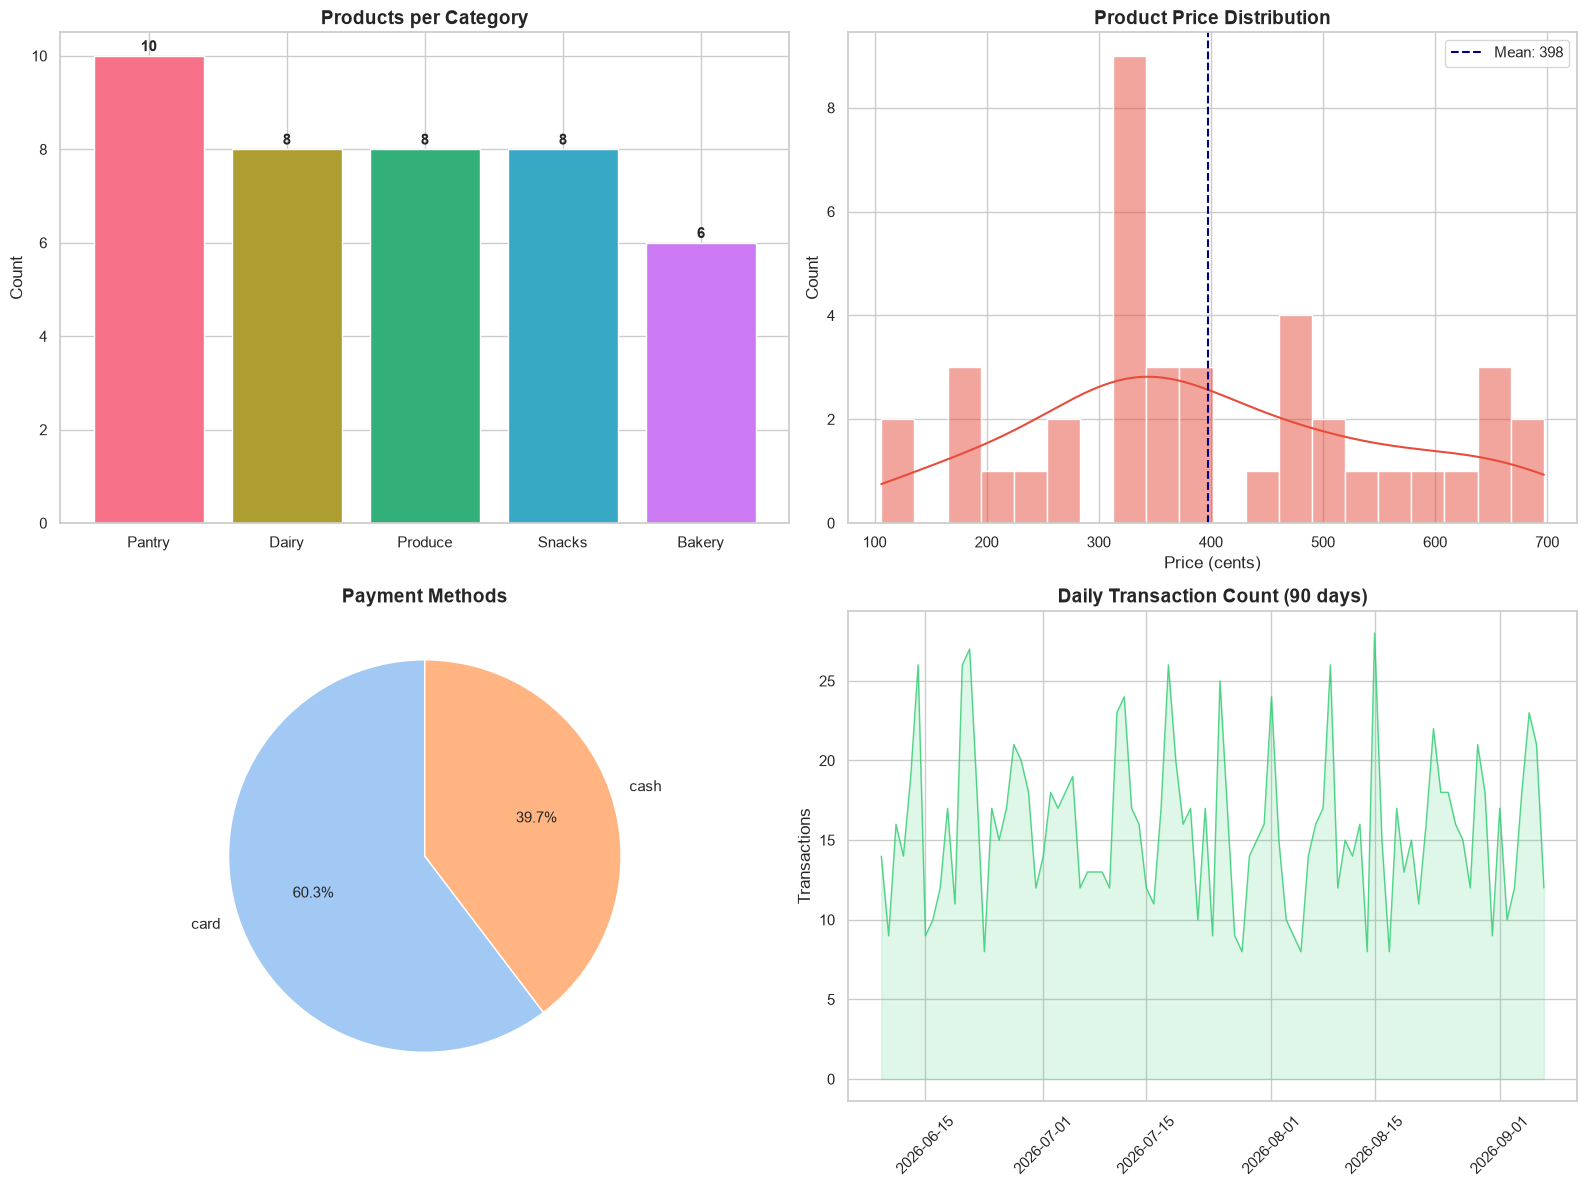

In [9]:
# EDA Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Products per category
cat_counts = products_df['category'].value_counts()
axes[0, 0].bar(cat_counts.index, cat_counts.values, color=sns.color_palette('husl', len(cat_counts)))
axes[0, 0].set_title('Products per Category', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Count')
for i, v in enumerate(cat_counts.values):
    axes[0, 0].text(i, v + 0.1, str(v), ha='center', fontweight='bold')

# 2. Price distribution
sns.histplot(products_df['unit_price_cents'], bins=20, kde=True, ax=axes[0, 1], color='#e74c3c')
axes[0, 1].set_title('Product Price Distribution', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Price (cents)')
axes[0, 1].axvline(products_df['unit_price_cents'].mean(), color='navy', linestyle='--', label=f"Mean: {products_df['unit_price_cents'].mean():.0f}")
axes[0, 1].legend()

# 3. Payment method breakdown
payment_counts = transactions_df['payment_method'].value_counts()
axes[1, 0].pie(payment_counts.values, labels=payment_counts.index, autopct='%1.1f%%',
               colors=sns.color_palette('pastel'), startangle=90)
axes[1, 0].set_title('Payment Methods', fontsize=14, fontweight='bold')

# 4. Daily transaction count over 90 days
transactions_df['date'] = pd.to_datetime(transactions_df['created_at']).dt.date
daily_counts = transactions_df.groupby('date').size()
axes[1, 1].plot(daily_counts.index, daily_counts.values, linewidth=1, alpha=0.8, color='#2ecc71')
axes[1, 1].fill_between(daily_counts.index, daily_counts.values, alpha=0.15, color='#2ecc71')
axes[1, 1].set_title('Daily Transaction Count (90 days)', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Transactions')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

---
## Section 4: Data Cleaning

Data cleaning involves:
1. **Removing duplicate records**
2. **Fixing data type inconsistencies**
3. **Removing invalid/corrupt entries**
4. **Standardizing formats**

In [10]:
# ═══════════════════════════════════════════════════════════════
# Section 4: Data Cleaning
# ═══════════════════════════════════════════════════════════════

print('=== Step 1: Detecting Duplicates ===')
print(f'Transaction items BEFORE dedup: {len(items_df)}')
dup_count = items_df.duplicated().sum()
print(f'Duplicate rows found: {dup_count}')

# Remove duplicates
items_df = items_df.drop_duplicates().reset_index(drop=True)
print(f'Transaction items AFTER dedup:  {len(items_df)}')

print('\n=== Step 2: Fixing Data Types ===')
print(f'unit_price_cents dtype BEFORE: {items_df["unit_price_cents"].dtype}')

# Ensure numeric columns are actually numeric
items_df['unit_price_cents'] = pd.to_numeric(items_df['unit_price_cents'], errors='coerce')
items_df['quantity'] = pd.to_numeric(items_df['quantity'], errors='coerce')
print(f'unit_price_cents dtype AFTER:  {items_df["unit_price_cents"].dtype}')

# Convert date columns to datetime
transactions_df['created_at'] = pd.to_datetime(transactions_df['created_at'])
batches_df['received_date'] = pd.to_datetime(batches_df['received_date'])
batches_df['expiry_date'] = pd.to_datetime(batches_df['expiry_date'])  # NaT for missing
movements_df['created_at'] = pd.to_datetime(movements_df['created_at'])

# Fix products reorder_point back to numeric
products_df['reorder_point'] = pd.to_numeric(products_df['reorder_point'], errors='coerce')

print('\n=== Step 3: Checking for Invalid Entries ===')
# Check for negative prices (invalid)
invalid_prices = items_df[items_df['unit_price_cents'] <= 0]
print(f'Items with invalid (<=0) prices: {len(invalid_prices)}')

# Check for zero-quantity items
zero_qty = items_df[items_df['quantity'] <= 0]
print(f'Items with zero/negative quantity: {len(zero_qty)}')

print('\n=== Step 4: Data Types After Cleaning ===')
print(products_df.dtypes)
print('\n\u2705 Data cleaning complete!')

=== Step 1: Detecting Duplicates ===
Transaction items BEFORE dedup: 3246
Duplicate rows found: 47
Transaction items AFTER dedup:  3199

=== Step 2: Fixing Data Types ===
unit_price_cents dtype BEFORE: int64
unit_price_cents dtype AFTER:  int64

=== Step 3: Checking for Invalid Entries ===
Items with invalid (<=0) prices: 0
Items with zero/negative quantity: 0

=== Step 4: Data Types After Cleaning ===
product_id              str
sku                     str
name                    str
category                str
unit                    str
reorder_point       float64
unit_cost_cents       int64
unit_price_cents      int64
dtype: object

✅ Data cleaning complete!


---
## Section 5: Handling Missing Values

Missing values can be handled using several strategies:
- **Deletion**: Remove rows/columns with missing values (if data loss is acceptable)
- **Mean/Median/Mode imputation**: Replace missing values with statistical measures
- **Forward-fill / Back-fill**: For time-series data, propagate last known value
- **Model-based imputation**: Use ML models to predict missing values

In [11]:
# ═══════════════════════════════════════════════════════════════
# Section 5: Handling Missing Values
# ═══════════════════════════════════════════════════════════════

print('=== Missing Value Analysis ===')
all_dfs = {
    'Products': products_df,
    'Batches': batches_df,
    'Transactions': transactions_df,
    'Transaction Items': items_df,
    'Stock Movements': movements_df,
}

for name, df in all_dfs.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        print(f'\n{name}:')
        for col, count in missing.items():
            pct = (count / len(df)) * 100
            print(f'  {col}: {count} missing ({pct:.1f}%)')

=== Missing Value Analysis ===

Products:
  reorder_point: 3 missing (7.5%)

Batches:
  expiry_date: 7 missing (5.8%)

Transactions:
  payment_method: 39 missing (2.7%)

Stock Movements:
  reason: 2511 missing (99.8%)


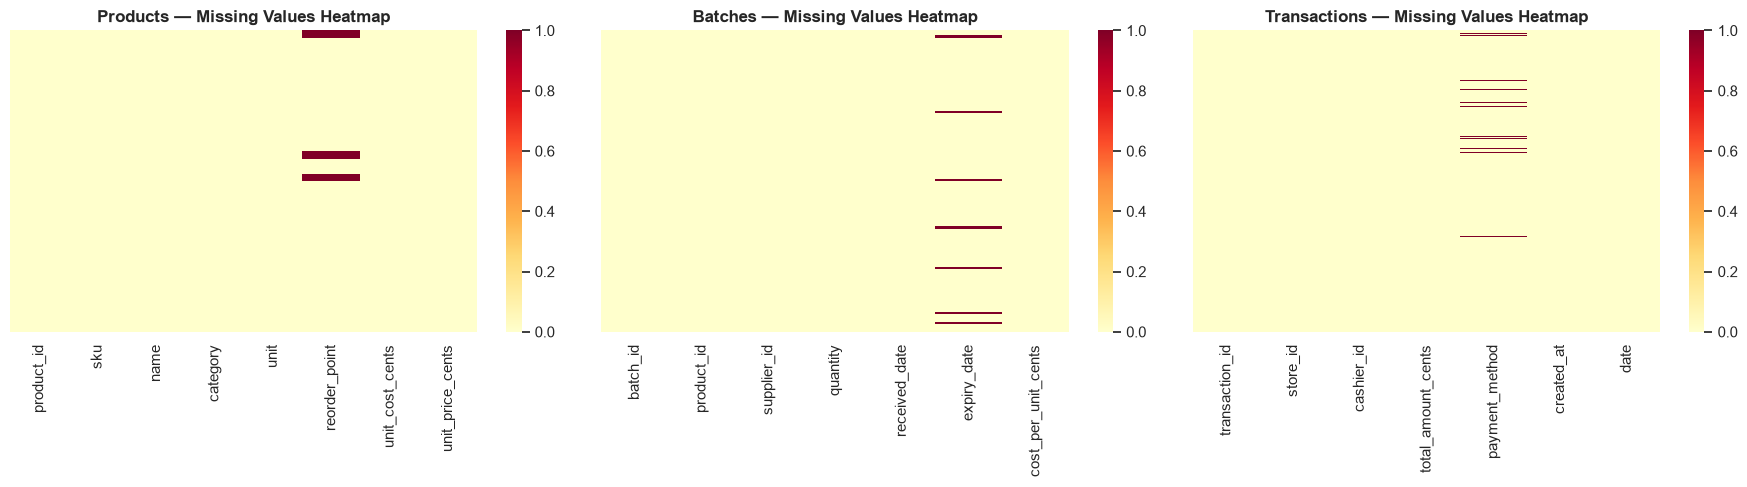

In [12]:
# Visualize missing values with a heatmap
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, df) in zip(axes, [('Products', products_df), ('Batches', batches_df), ('Transactions', transactions_df)]):
    sns.heatmap(df.isnull(), cbar=True, yticklabels=False, cmap='YlOrRd', ax=ax)
    ax.set_title(f'{name} — Missing Values Heatmap', fontweight='bold')

plt.tight_layout()
plt.show()

In [13]:
# Apply imputation strategies
print('=== Imputation Strategies ===')

# Strategy 1: Median imputation for reorder_point
median_reorder = products_df['reorder_point'].median()
print(f'\n1. Products reorder_point — Median imputation (median = {median_reorder})')
products_df['reorder_point'] = products_df['reorder_point'].fillna(median_reorder).astype(int)
print(f'   Missing after imputation: {products_df["reorder_point"].isnull().sum()}')

# Strategy 2: Forward-fill for batch expiry dates (time-series concept)
print(f'\n2. Batches expiry_date — Forward-fill imputation')
batches_df = batches_df.sort_values(['product_id', 'received_date'])
batches_df['expiry_date'] = batches_df.groupby('product_id')['expiry_date'].ffill()
# Any remaining NaN (first batch of product) → fill with received_date + 14 days
mask = batches_df['expiry_date'].isna()
batches_df.loc[mask, 'expiry_date'] = batches_df.loc[mask, 'received_date'] + pd.Timedelta(days=14)
print(f'   Missing after imputation: {batches_df["expiry_date"].isnull().sum()}')

# Strategy 3: Mode imputation for payment_method
mode_payment = transactions_df['payment_method'].mode()[0]
print(f'\n3. Transactions payment_method — Mode imputation (mode = \"{mode_payment}\")')
transactions_df['payment_method'] = transactions_df['payment_method'].fillna(mode_payment)
print(f'   Missing after imputation: {transactions_df["payment_method"].isnull().sum()}')

# Strategy 4: Constant fill for stock movement reasons
print(f'\n4. Stock movements reason — Constant fill (\"Normal sale\")')
movements_df['reason'] = movements_df['reason'].fillna('Normal sale')
print(f'   Missing after imputation: {movements_df["reason"].isnull().sum()}')

# Using Scikit-Learn SimpleImputer (demonstration)
print('\n=== Scikit-Learn SimpleImputer Demo ===')
imputer = SimpleImputer(strategy='median')
demo_values = np.array([[100], [np.nan], [200], [150], [np.nan], [300]])
print(f'Before: {demo_values.flatten()}')
imputed = imputer.fit_transform(demo_values)
print(f'After (median imputation): {imputed.flatten()}')

print('\n\u2705 All missing values handled!')

=== Imputation Strategies ===

1. Products reorder_point — Median imputation (median = 20.0)
   Missing after imputation: 0

2. Batches expiry_date — Forward-fill imputation
   Missing after imputation: 0

3. Transactions payment_method — Mode imputation (mode = "card")
   Missing after imputation: 0

4. Stock movements reason — Constant fill ("Normal sale")
   Missing after imputation: 0

=== Scikit-Learn SimpleImputer Demo ===
Before: [100.  nan 200. 150.  nan 300.]
After (median imputation): [100. 175. 200. 150. 175. 300.]

✅ All missing values handled!


---
## Section 6: Data Integration

Data integration combines data from multiple sources into a single, unified view. We merge our separate DataFrames:
- **Products + Transaction Items** → know what was sold and at what price
- **+ Transactions** → know when and how it was sold
- **+ Batches** → know batch/expiry information

This creates a comprehensive analytics DataFrame.

In [14]:
# ═══════════════════════════════════════════════════════════════
# Section 6: Data Integration
# ═══════════════════════════════════════════════════════════════

print('=== Merging DataFrames ===')

# Step 1: Merge transaction_items with products
merged = items_df.merge(
    products_df[['product_id', 'name', 'category', 'unit_cost_cents', 'unit_price_cents', 'reorder_point']],
    on='product_id',
    how='left',
    suffixes=('_item', '_product')
)
print(f'After merging items + products: {merged.shape}')

# Step 2: Merge with transactions (for date and payment info)
merged = merged.merge(
    transactions_df[['transaction_id', 'total_amount_cents', 'payment_method', 'created_at']],
    on='transaction_id',
    how='left'
)
print(f'After merging + transactions:   {merged.shape}')

# Step 3: Create product-level daily aggregation
merged['sale_date'] = pd.to_datetime(merged['created_at']).dt.date
merged['revenue_cents'] = merged['quantity'] * merged['unit_price_cents_item']

daily_product_sales = merged.groupby(['product_id', 'name', 'category', 'sale_date']).agg(
    total_qty=('quantity', 'sum'),
    total_revenue=('revenue_cents', 'sum'),
    n_transactions=('transaction_id', 'nunique'),
    avg_price=('unit_price_cents_item', 'mean'),
    unit_cost=('unit_cost_cents', 'first'),
    reorder_point=('reorder_point', 'first'),
).reset_index()

daily_product_sales['sale_date'] = pd.to_datetime(daily_product_sales['sale_date'])

print(f'\nIntegrated daily product sales: {daily_product_sales.shape}')
print(f'Date range: {daily_product_sales["sale_date"].min()} to {daily_product_sales["sale_date"].max()}')
display(daily_product_sales.head(10))

=== Merging DataFrames ===
After merging items + products: (3199, 11)
After merging + transactions:   (3199, 14)

Integrated daily product sales: (2039, 10)
Date range: 2026-06-09 00:00:00 to 2026-09-07 00:00:00


,product_id,name,category,sale_date,total_qty,total_revenue,n_transactions,avg_price,unit_cost,reorder_point
0,022278a903bb,Carrots 500g,Produce,2026-06-13,3,1110,1,370.0,359,21
1,022278a903bb,Carrots 500g,Produce,2026-06-15,3,1110,1,370.0,359,21
2,022278a903bb,Carrots 500g,Produce,2026-06-16,1,370,1,370.0,359,21
3,022278a903bb,Carrots 500g,Produce,2026-06-17,1,370,1,370.0,359,21
4,022278a903bb,Carrots 500g,Produce,2026-06-18,1,370,1,370.0,359,21
5,022278a903bb,Carrots 500g,Produce,2026-06-20,3,1110,1,370.0,359,21
6,022278a903bb,Carrots 500g,Produce,2026-06-21,2,740,1,370.0,359,21
7,022278a903bb,Carrots 500g,Produce,2026-06-25,1,370,1,370.0,359,21
8,022278a903bb,Carrots 500g,Produce,2026-06-26,4,1480,1,370.0,359,21
9,022278a903bb,Carrots 500g,Produce,2026-06-27,3,1110,1,370.0,359,21


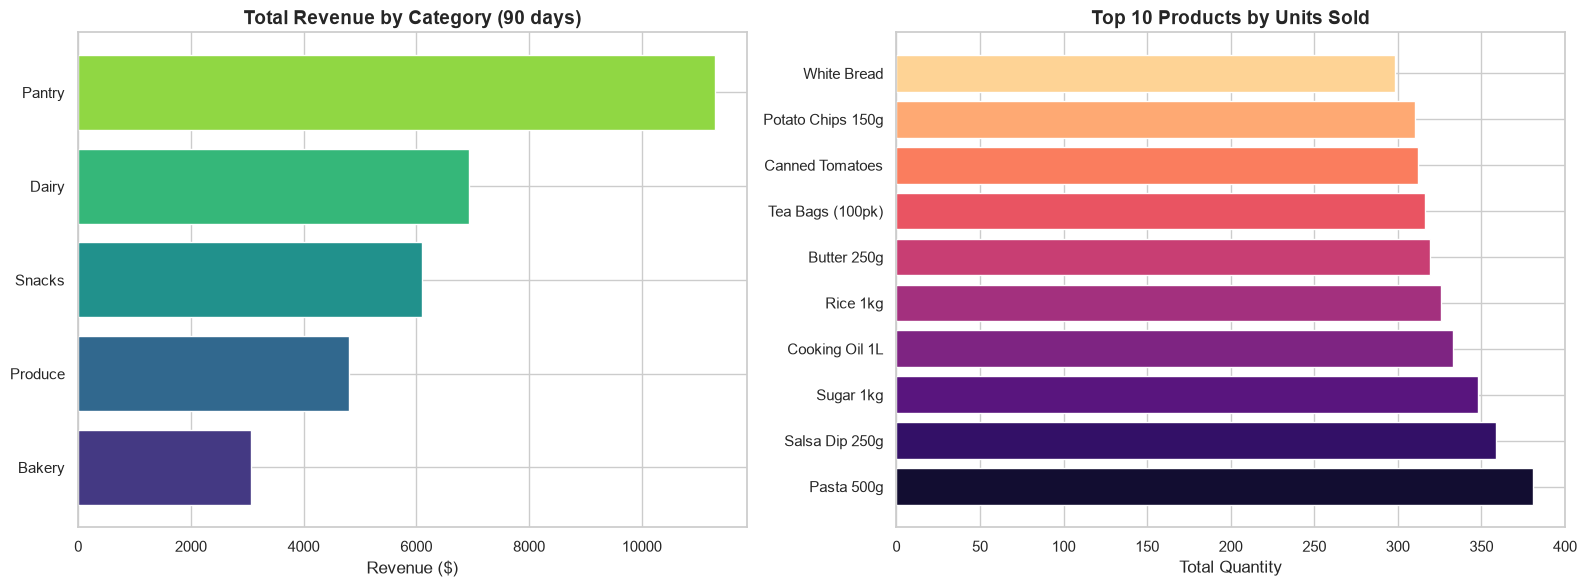

In [15]:
# Visualize integrated data
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Revenue by category
cat_revenue = daily_product_sales.groupby('category')['total_revenue'].sum().sort_values(ascending=True)
axes[0].barh(cat_revenue.index, cat_revenue.values / 100, color=sns.color_palette('viridis', len(cat_revenue)))
axes[0].set_title('Total Revenue by Category (90 days)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Revenue ($)')

# Top 10 selling products
top_products = daily_product_sales.groupby('name')['total_qty'].sum().nlargest(10)
axes[1].barh(top_products.index, top_products.values, color=sns.color_palette('magma', 10))
axes[1].set_title('Top 10 Products by Units Sold', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Quantity')

plt.tight_layout()
plt.show()

---
## Section 7: Data Transformation

Data transformation modifies the data to make it more suitable for analysis and modeling:

1. **Log transformation** — reduces skewness in heavily right-skewed distributions
2. **Label Encoding** — converts categorical variables to numeric (ordinal)
3. **One-Hot Encoding** — creates binary columns for each category (nominal)

=== Log Transformation ===
total_revenue skewness BEFORE: 1.859
log_revenue skewness AFTER:    -0.236


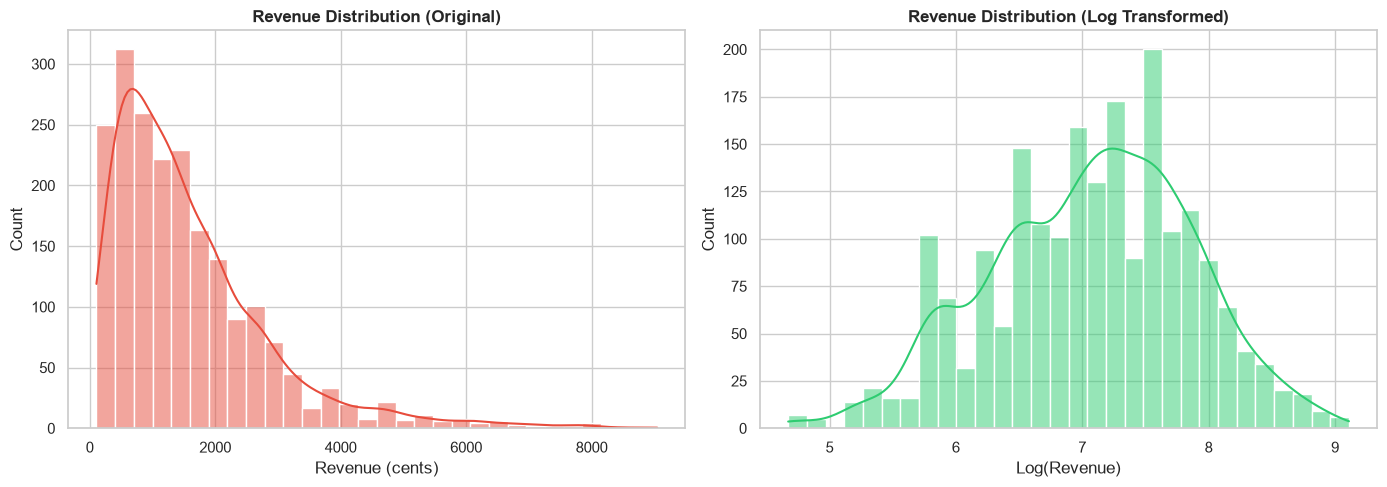

In [16]:
# ═══════════════════════════════════════════════════════════════
# Section 7: Data Transformation
# ═══════════════════════════════════════════════════════════════

analytics_df = daily_product_sales.copy()

# === 7a: Log Transformation ===
print('=== Log Transformation ===')
print(f'total_revenue skewness BEFORE: {analytics_df["total_revenue"].skew():.3f}')

analytics_df['log_revenue'] = np.log1p(analytics_df['total_revenue'])
analytics_df['log_qty'] = np.log1p(analytics_df['total_qty'])

print(f'log_revenue skewness AFTER:    {analytics_df["log_revenue"].skew():.3f}')

# Visualize before/after
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(analytics_df['total_revenue'], bins=30, kde=True, ax=axes[0], color='#e74c3c')
axes[0].set_title('Revenue Distribution (Original)', fontweight='bold')
axes[0].set_xlabel('Revenue (cents)')

sns.histplot(analytics_df['log_revenue'], bins=30, kde=True, ax=axes[1], color='#2ecc71')
axes[1].set_title('Revenue Distribution (Log Transformed)', fontweight='bold')
axes[1].set_xlabel('Log(Revenue)')

plt.tight_layout()
plt.show()

In [17]:
# === 7b: Label Encoding (ordinal categories) ===
print('=== Label Encoding ===')
le = LabelEncoder()
analytics_df['category_encoded'] = le.fit_transform(analytics_df['category'])

print('Category → Encoded value mapping:')
for cls, label in zip(le.classes_, range(len(le.classes_))):
    print(f'  {cls} → {label}')

# === 7c: One-Hot Encoding (nominal categories) ===
print('\n=== One-Hot Encoding ===')
category_dummies = pd.get_dummies(analytics_df['category'], prefix='cat')
print(f'Created {len(category_dummies.columns)} binary columns:')
print(f'  Columns: {list(category_dummies.columns)}')
display(category_dummies.head())

# Add to analytics dataframe
analytics_df = pd.concat([analytics_df, category_dummies], axis=1)
print(f'\nAnalytics DataFrame shape after encoding: {analytics_df.shape}')

=== Label Encoding ===
Category → Encoded value mapping:
  Bakery → 0
  Dairy → 1
  Pantry → 2
  Produce → 3
  Snacks → 4

=== One-Hot Encoding ===
Created 5 binary columns:
  Columns: ['cat_Bakery', 'cat_Dairy', 'cat_Pantry', 'cat_Produce', 'cat_Snacks']


,cat_Bakery,cat_Dairy,cat_Pantry,cat_Produce,cat_Snacks
0,False,False,False,True,False
1,False,False,False,True,False
2,False,False,False,True,False
3,False,False,False,True,False
4,False,False,False,True,False



Analytics DataFrame shape after encoding: (2039, 18)


---
## Section 8: Data Reduction

Data reduction decreases the volume of data while maintaining its analytical value:

1. **Correlation-based elimination** — remove highly correlated features (redundant information)
2. **PCA (Principal Component Analysis)** — project data into lower-dimensional space
3. **Aggregation** — summarize detailed data at a higher level

=== Correlation-based Feature Reduction ===


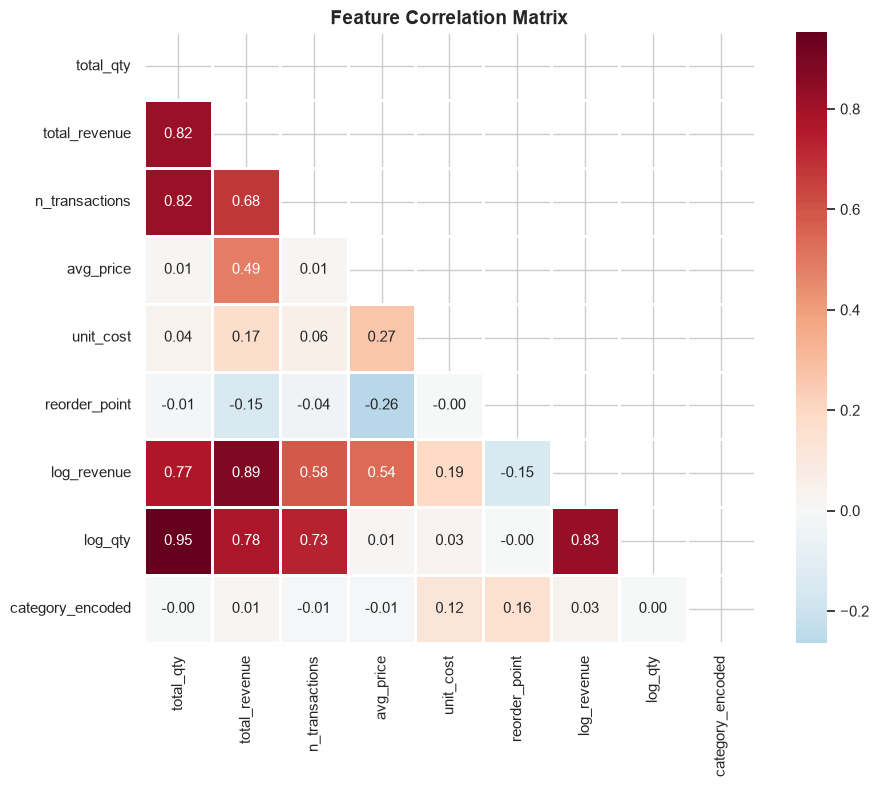


Highly correlated feature pairs (|r| > 0.9):
  total_qty <-> log_qty: 0.952

→ Highly correlated features (e.g. total_revenue & log_revenue) can be removed to reduce redundancy.


In [18]:
# ═══════════════════════════════════════════════════════════════
# Section 8: Data Reduction
# ═══════════════════════════════════════════════════════════════

# === 8a: Correlation Analysis ===
print('=== Correlation-based Feature Reduction ===')

numeric_cols = ['total_qty', 'total_revenue', 'n_transactions', 'avg_price',
                'unit_cost', 'reorder_point', 'log_revenue', 'log_qty', 'category_encoded']
corr_matrix = analytics_df[numeric_cols].corr()

# Heatmap
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=1)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Identify highly correlated pairs (> 0.9)
print('\nHighly correlated feature pairs (|r| > 0.9):')
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.9:
            print(f'  {corr_matrix.columns[i]} <-> {corr_matrix.columns[j]}: {corr_matrix.iloc[i, j]:.3f}')

print('\n→ Highly correlated features (e.g. total_revenue & log_revenue) can be removed to reduce redundancy.')

=== PCA Dimensionality Reduction ===

Original features: 6

Explained variance ratio per component:
  PC1: 0.4410 (44.1%)  |  Cumulative: 0.4410 (44.1%)
  PC2: 0.2345 (23.5%)  |  Cumulative: 0.6755 (67.5%)
  PC3: 0.1665 (16.7%)  |  Cumulative: 0.8420 (84.2%)
  PC4: 0.1132 (11.3%)  |  Cumulative: 0.9552 (95.5%)
  PC5: 0.0369 (3.7%)  |  Cumulative: 0.9920 (99.2%)
  PC6: 0.0080 (0.8%)  |  Cumulative: 1.0000 (100.0%)


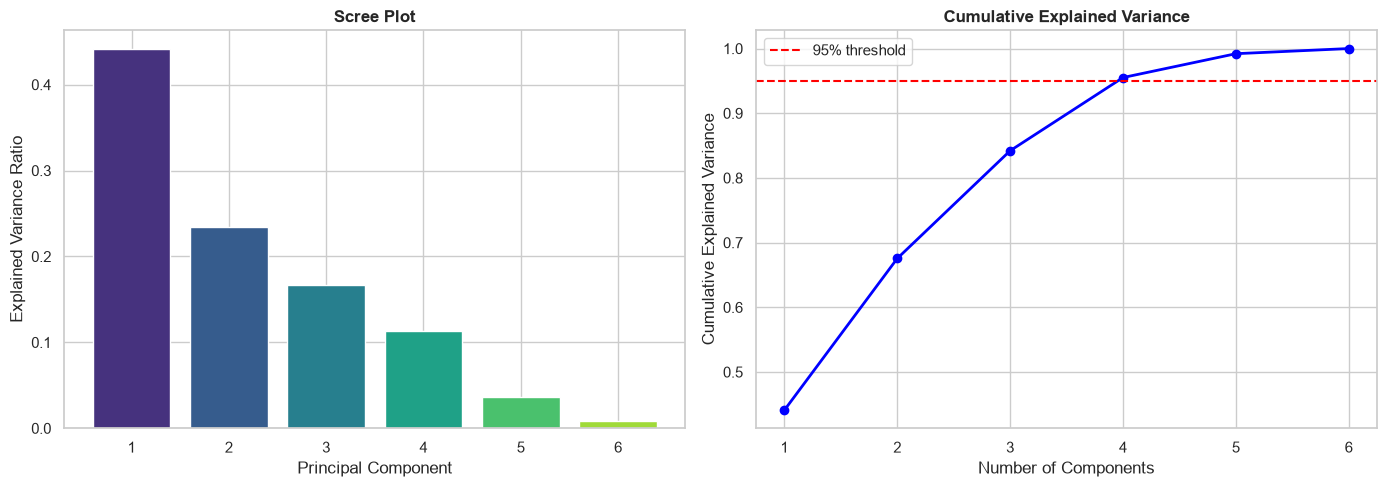


→ 4 components explain ≥95% of variance (reduced from 6 features)


In [19]:
# === 8b: PCA for Dimensionality Reduction ===
print('=== PCA Dimensionality Reduction ===')

# Select features for PCA
pca_features = ['total_qty', 'total_revenue', 'n_transactions', 'avg_price', 'unit_cost', 'reorder_point']
X_pca = analytics_df[pca_features].copy()

# Standardize before PCA (PCA is sensitive to scale)
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca)

# Fit PCA
pca = PCA()
X_pca_transformed = pca.fit_transform(X_pca_scaled)

# Explained variance
print(f'\nOriginal features: {len(pca_features)}')
print('\nExplained variance ratio per component:')
for i, (var, cum) in enumerate(zip(pca.explained_variance_ratio_, np.cumsum(pca.explained_variance_ratio_))):
    print(f'  PC{i+1}: {var:.4f} ({var*100:.1f}%)  |  Cumulative: {cum:.4f} ({cum*100:.1f}%)')

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_,
            color=sns.color_palette('viridis', len(pca.explained_variance_ratio_)))
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot', fontweight='bold')

axes[1].plot(range(1, len(pca.explained_variance_ratio_) + 1),
             np.cumsum(pca.explained_variance_ratio_), 'bo-', linewidth=2)
axes[1].axhline(y=0.95, color='r', linestyle='--', label='95% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance')
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

# Determine optimal number of components (95% variance)
n_components_95 = np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1
print(f'\n→ {n_components_95} components explain ≥95% of variance (reduced from {len(pca_features)} features)')

---
## Section 9: Feature Scaling

Feature scaling ensures that all features contribute equally to the model by bringing them to a comparable range.

### Two main approaches:

| Method | Formula | Range | When to Use |
|---|---|---|---|
| **Min-Max Normalization** | (x - min) / (max - min) | [0, 1] | When you need bounded values, neural networks |
| **Z-Score Standardization** | (x - μ) / σ | unbounded | When data follows normal distribution, SVM/PCA |

In [20]:
# ═══════════════════════════════════════════════════════════════
# Section 9: Feature Scaling
# ═══════════════════════════════════════════════════════════════

scale_features = ['total_qty', 'total_revenue', 'avg_price', 'unit_cost', 'reorder_point']
X_scale = analytics_df[scale_features].copy()

print('=== Before Scaling ===')
display(X_scale.describe().round(2))

# === 9a: Min-Max Normalization ===
minmax_scaler = MinMaxScaler()
X_normalized = pd.DataFrame(
    minmax_scaler.fit_transform(X_scale),
    columns=[f'{col}_norm' for col in scale_features]
)

print('\n=== After Min-Max Normalization (range [0, 1]) ===')
display(X_normalized.describe().round(4))

# === 9b: Z-Score Standardization ===
std_scaler = StandardScaler()
X_standardized = pd.DataFrame(
    std_scaler.fit_transform(X_scale),
    columns=[f'{col}_std' for col in scale_features]
)

print('\n=== After Z-Score Standardization (mean≈0, std≈1) ===')
display(X_standardized.describe().round(4))

=== Before Scaling ===


,total_qty,total_revenue,avg_price,unit_cost,reorder_point
count,2039.00,2039.00,2039.00,2039.00,2039.00
mean,3.93,1578.75,400.51,220.71,20.79
std,2.57,1266.42,155.24,100.11,6.17
min,1.00,106.00,106.00,63.00,11.00
25%,2.00,658.00,316.00,121.00,16.00
50%,3.00,1268.00,370.00,235.00,20.00
75%,5.00,2040.00,510.00,305.00,27.00
max,17.00,9044.00,697.00,393.00,30.00



=== After Min-Max Normalization (range [0, 1]) ===


,total_qty_norm,total_revenue_norm,avg_price_norm,unit_cost_norm,reorder_point_norm
count,2039.0000,2039.0000,2039.0000,2039.0000,2039.0000
mean,0.1833,0.1648,0.4983,0.4779,0.5155
std,0.1604,0.1417,0.2627,0.3034,0.3245
min,0.0000,0.0000,0.0000,0.0000,0.0000
25%,0.0625,0.0618,0.3553,0.1758,0.2632
50%,0.1250,0.1300,0.4467,0.5212,0.4737
75%,0.2500,0.2164,0.6836,0.7333,0.8421
max,1.0000,1.0000,1.0000,1.0000,1.0000



=== After Z-Score Standardization (mean≈0, std≈1) ===


,total_qty_std,total_revenue_std,avg_price_std,unit_cost_std,reorder_point_std
count,2039.0000,2039.0000,2039.0000,2039.0000,2039.0000
mean,0.0000,0.0000,0.0000,-0.0000,0.0000
std,1.0002,1.0002,1.0002,1.0002,1.0002
min,-1.1432,-1.1632,-1.8976,-1.5758,-1.5891
25%,-0.7534,-0.7272,-0.5445,-0.9963,-0.7779
50%,-0.3636,-0.2454,-0.1966,0.1428,-0.1289
75%,0.4160,0.3643,0.7054,0.8422,1.0068
max,5.0935,5.8962,1.9103,1.7215,1.4935


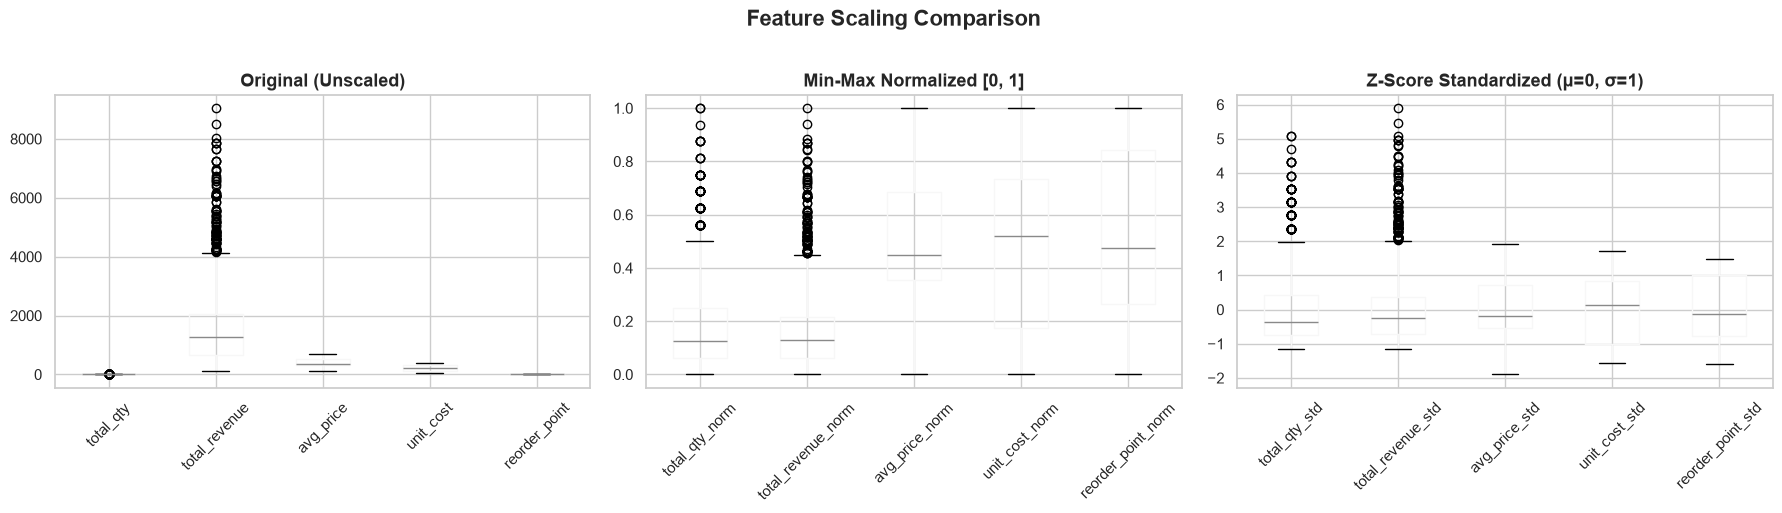

In [21]:
# Visual comparison: Original vs Normalized vs Standardized
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original
X_scale.boxplot(ax=axes[0])
axes[0].set_title('Original (Unscaled)', fontweight='bold', fontsize=13)
axes[0].tick_params(axis='x', rotation=45)

# Normalized
X_normalized.boxplot(ax=axes[1])
axes[1].set_title('Min-Max Normalized [0, 1]', fontweight='bold', fontsize=13)
axes[1].tick_params(axis='x', rotation=45)

# Standardized
X_standardized.boxplot(ax=axes[2])
axes[2].set_title('Z-Score Standardized (μ=0, σ=1)', fontweight='bold', fontsize=13)
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Feature Scaling Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Section 10: Feature Engineering

Feature engineering is the process of creating new, informative features from existing data. Good features capture domain knowledge and improve model performance.

For GroceryIQ, we engineer features relevant to **demand forecasting**:

In [22]:
# ═══════════════════════════════════════════════════════════════
# Section 10: Feature Engineering
# ═══════════════════════════════════════════════════════════════

fe_df = analytics_df.copy()

# === 10a: Time-based features ===
print('=== Time-based Features ===')
fe_df['day_of_week'] = fe_df['sale_date'].dt.dayofweek      # 0=Monday, 6=Sunday
fe_df['day_name'] = fe_df['sale_date'].dt.day_name()
fe_df['is_weekend'] = (fe_df['day_of_week'] >= 5).astype(int)
fe_df['month'] = fe_df['sale_date'].dt.month
fe_df['week_of_year'] = fe_df['sale_date'].dt.isocalendar().week.astype(int)
fe_df['day_of_month'] = fe_df['sale_date'].dt.day
fe_df['is_month_start'] = (fe_df['day_of_month'] <= 5).astype(int)
fe_df['is_month_end'] = (fe_df['day_of_month'] >= 25).astype(int)

print('Time features created: day_of_week, is_weekend, month, week_of_year, day_of_month, is_month_start, is_month_end')

# === 10b: Revenue & profit features ===
print('\n=== Revenue & Profit Features ===')
fe_df['revenue_per_unit'] = fe_df['total_revenue'] / fe_df['total_qty']
fe_df['profit_margin_cents'] = fe_df['avg_price'] - fe_df['unit_cost']
fe_df['profit_margin_pct'] = (fe_df['profit_margin_cents'] / fe_df['avg_price'] * 100).round(2)
fe_df['total_profit'] = fe_df['profit_margin_cents'] * fe_df['total_qty']

print('Profit features created: revenue_per_unit, profit_margin_cents, profit_margin_pct, total_profit')

# === 10c: Rolling window features (lag features) ===
print('\n=== Rolling Window / Lag Features ===')
fe_df = fe_df.sort_values(['product_id', 'sale_date'])

fe_df['qty_lag_1'] = fe_df.groupby('product_id')['total_qty'].shift(1)
fe_df['qty_lag_7'] = fe_df.groupby('product_id')['total_qty'].shift(7)
fe_df['qty_rolling_3d_avg'] = fe_df.groupby('product_id')['total_qty'].transform(
    lambda x: x.rolling(3, min_periods=1).mean()
)
fe_df['qty_rolling_7d_avg'] = fe_df.groupby('product_id')['total_qty'].transform(
    lambda x: x.rolling(7, min_periods=1).mean()
)
fe_df['qty_rolling_7d_std'] = fe_df.groupby('product_id')['total_qty'].transform(
    lambda x: x.rolling(7, min_periods=1).std()
)

# Percentage change
fe_df['qty_pct_change'] = fe_df.groupby('product_id')['total_qty'].pct_change()

print('Lag features created: qty_lag_1, qty_lag_7, qty_rolling_3d_avg, qty_rolling_7d_avg, qty_rolling_7d_std, qty_pct_change')

# === 10d: Interaction features ===
print('\n=== Interaction Features ===')
fe_df['weekend_x_qty'] = fe_df['is_weekend'] * fe_df['total_qty']
fe_df['price_x_qty'] = fe_df['avg_price'] * fe_df['total_qty']

print('Interaction features created: weekend_x_qty, price_x_qty')

print(f'\n\u2705 Feature engineering complete!')
print(f'DataFrame shape: {fe_df.shape} ({fe_df.shape[1]} features)')
print(f'\nNew features added:')
new_cols = [c for c in fe_df.columns if c not in analytics_df.columns]
for i, col in enumerate(new_cols, 1):
    print(f'  {i:2d}. {col}')

=== Time-based Features ===
Time features created: day_of_week, is_weekend, month, week_of_year, day_of_month, is_month_start, is_month_end

=== Revenue & Profit Features ===
Profit features created: revenue_per_unit, profit_margin_cents, profit_margin_pct, total_profit

=== Rolling Window / Lag Features ===
Lag features created: qty_lag_1, qty_lag_7, qty_rolling_3d_avg, qty_rolling_7d_avg, qty_rolling_7d_std, qty_pct_change

=== Interaction Features ===
Interaction features created: weekend_x_qty, price_x_qty

✅ Feature engineering complete!
DataFrame shape: (2039, 38) (38 features)

New features added:
   1. day_of_week
   2. day_name
   3. is_weekend
   4. month
   5. week_of_year
   6. day_of_month
   7. is_month_start
   8. is_month_end
   9. revenue_per_unit
  10. profit_margin_cents
  11. profit_margin_pct
  12. total_profit
  13. qty_lag_1
  14. qty_lag_7
  15. qty_rolling_3d_avg
  16. qty_rolling_7d_avg
  17. qty_rolling_7d_std
  18. qty_pct_change
  19. weekend_x_qty
  20. pr

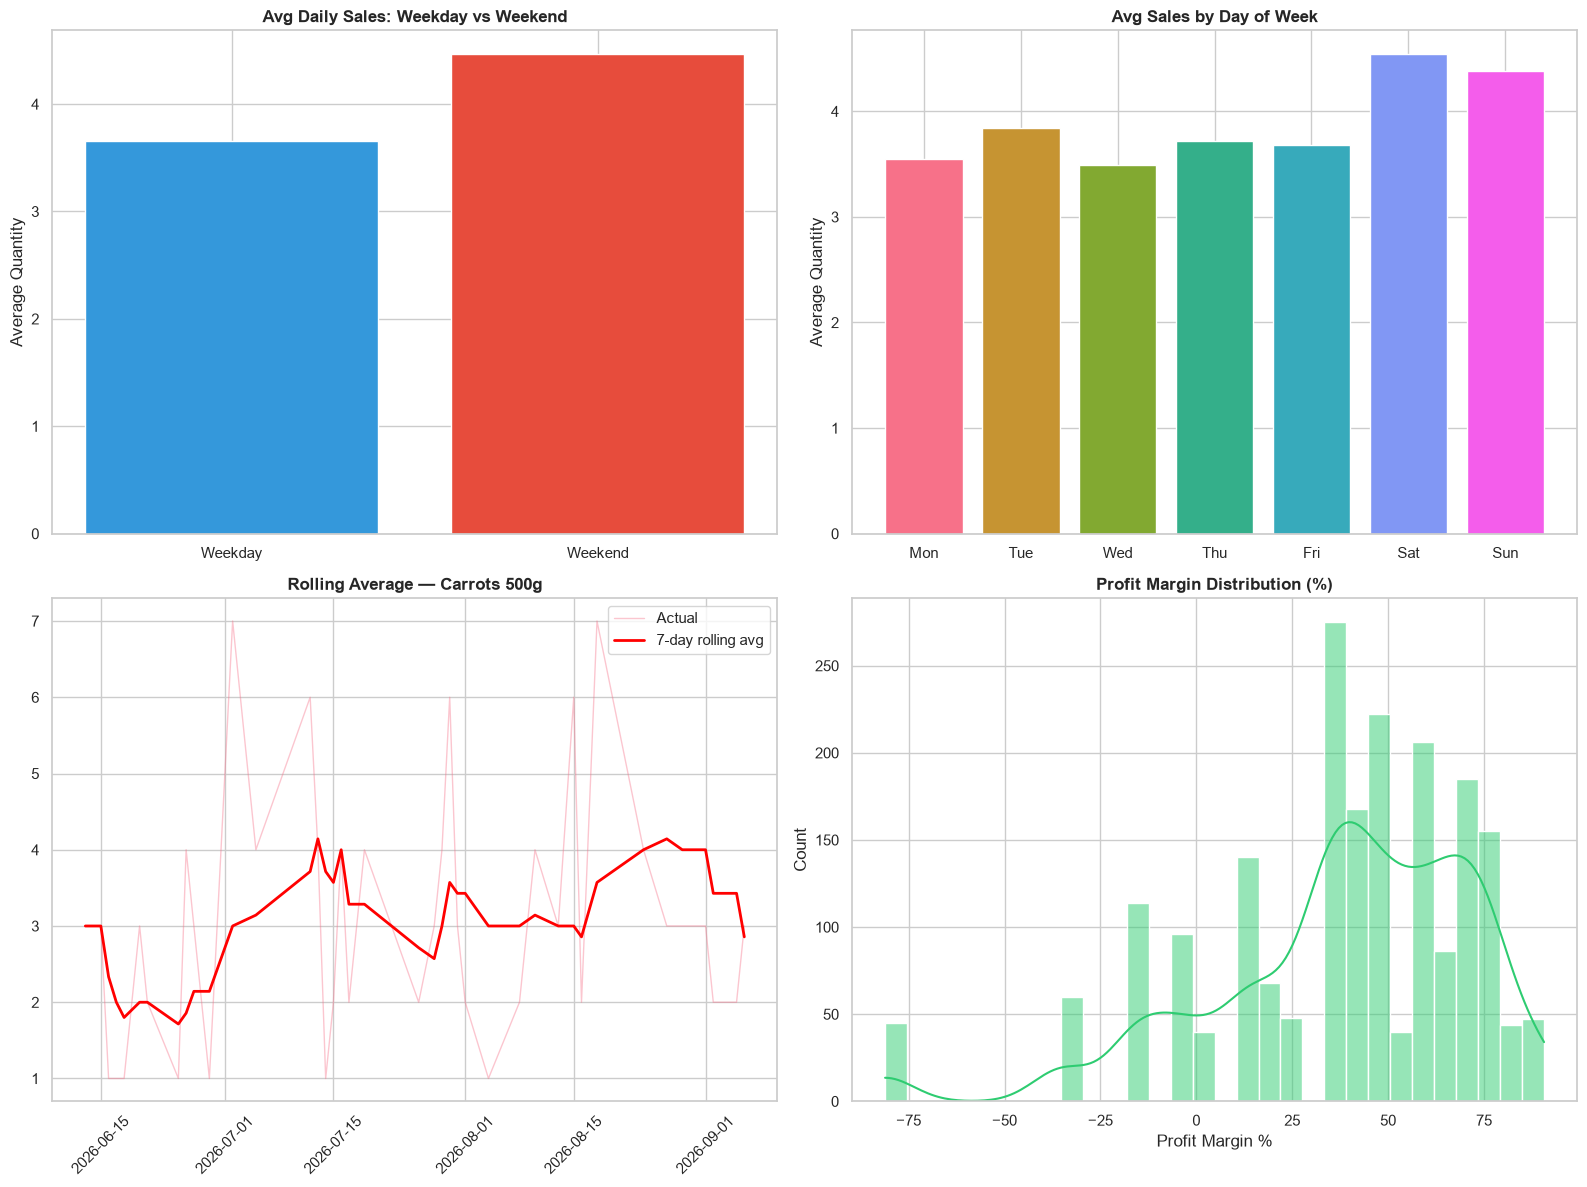

In [23]:
# Visualize engineered features
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Weekend vs weekday sales
weekend_sales = fe_df.groupby('is_weekend')['total_qty'].mean()
axes[0, 0].bar(['Weekday', 'Weekend'], weekend_sales.values, color=['#3498db', '#e74c3c'])
axes[0, 0].set_title('Avg Daily Sales: Weekday vs Weekend', fontweight='bold')
axes[0, 0].set_ylabel('Average Quantity')

# Sales by day of week
dow_sales = fe_df.groupby('day_of_week')['total_qty'].mean()
day_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
axes[0, 1].bar(day_labels, dow_sales.values, color=sns.color_palette('husl', 7))
axes[0, 1].set_title('Avg Sales by Day of Week', fontweight='bold')
axes[0, 1].set_ylabel('Average Quantity')

# Rolling average example (one product)
sample_product = fe_df[fe_df['name'] == fe_df['name'].iloc[0]].head(60)
axes[1, 0].plot(sample_product['sale_date'], sample_product['total_qty'], alpha=0.4, label='Actual', linewidth=1)
axes[1, 0].plot(sample_product['sale_date'], sample_product['qty_rolling_7d_avg'], color='red', linewidth=2, label='7-day rolling avg')
axes[1, 0].set_title(f'Rolling Average — {sample_product["name"].iloc[0]}', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].tick_params(axis='x', rotation=45)

# Profit margin distribution
sns.histplot(fe_df['profit_margin_pct'].dropna(), bins=30, kde=True, ax=axes[1, 1], color='#2ecc71')
axes[1, 1].set_title('Profit Margin Distribution (%)', fontweight='bold')
axes[1, 1].set_xlabel('Profit Margin %')

plt.tight_layout()
plt.show()

---
## Section 11: Feature Selection

Feature selection identifies the most relevant features for the prediction task, reducing noise and improving model performance.

Methods:
1. **Correlation with target** — simple linear relationship
2. **Mutual Information** — captures non-linear dependencies
3. **SelectKBest** — selects top K features using a scoring function

In [24]:
# ═══════════════════════════════════════════════════════════════
# Section 11: Feature Selection
# ═══════════════════════════════════════════════════════════════

# Prepare feature matrix — drop non-numeric and target-leaking columns
target = 'total_qty'
exclude_cols = ['product_id', 'name', 'category', 'sale_date', 'day_name',
                'total_qty', 'total_revenue', 'log_revenue', 'log_qty',
                'revenue_cents', 'revenue_per_unit', 'total_profit',
                'price_x_qty', 'weekend_x_qty']

feature_cols = [c for c in fe_df.columns if c not in exclude_cols and fe_df[c].dtype in ['int64', 'float64', 'int32', 'float32', 'bool', 'uint32']]
print(f'Candidate features ({len(feature_cols)}):')
for i, col in enumerate(feature_cols, 1):
    print(f'  {i:2d}. {col}')

# Drop rows with NaN (from lag features at the start of each product's series)
fs_df = fe_df[feature_cols + [target]].dropna()
X_fs = fs_df[feature_cols]
y_fs = fs_df[target]

print(f'\nFeature selection dataset: {X_fs.shape[0]} rows × {X_fs.shape[1]} features')

Candidate features (25):
   1. n_transactions
   2. avg_price
   3. unit_cost
   4. reorder_point
   5. category_encoded
   6. cat_Bakery
   7. cat_Dairy
   8. cat_Pantry
   9. cat_Produce
  10. cat_Snacks
  11. day_of_week
  12. is_weekend
  13. month
  14. week_of_year
  15. day_of_month
  16. is_month_start
  17. is_month_end
  18. profit_margin_cents
  19. profit_margin_pct
  20. qty_lag_1
  21. qty_lag_7
  22. qty_rolling_3d_avg
  23. qty_rolling_7d_avg
  24. qty_rolling_7d_std
  25. qty_pct_change

Feature selection dataset: 1759 rows × 25 features


=== Correlation with Target (total_qty) ===
n_transactions         0.822440
qty_rolling_3d_avg     0.619266
qty_pct_change         0.541617
qty_rolling_7d_avg     0.418020
qty_rolling_7d_std     0.308564
cat_Pantry             0.139540
is_weekend             0.138232
day_of_week            0.113268
qty_lag_1              0.099735
cat_Produce            0.066822
week_of_year           0.058722
cat_Dairy              0.048245
is_month_end           0.040552
unit_cost              0.038359
cat_Bakery             0.037817
month                  0.033523
qty_lag_7              0.032371
day_of_month           0.029159
profit_margin_pct      0.023711
profit_margin_cents    0.022749
reorder_point          0.020359
cat_Snacks             0.018404
category_encoded       0.003787
avg_price              0.001226
is_month_start         0.000159


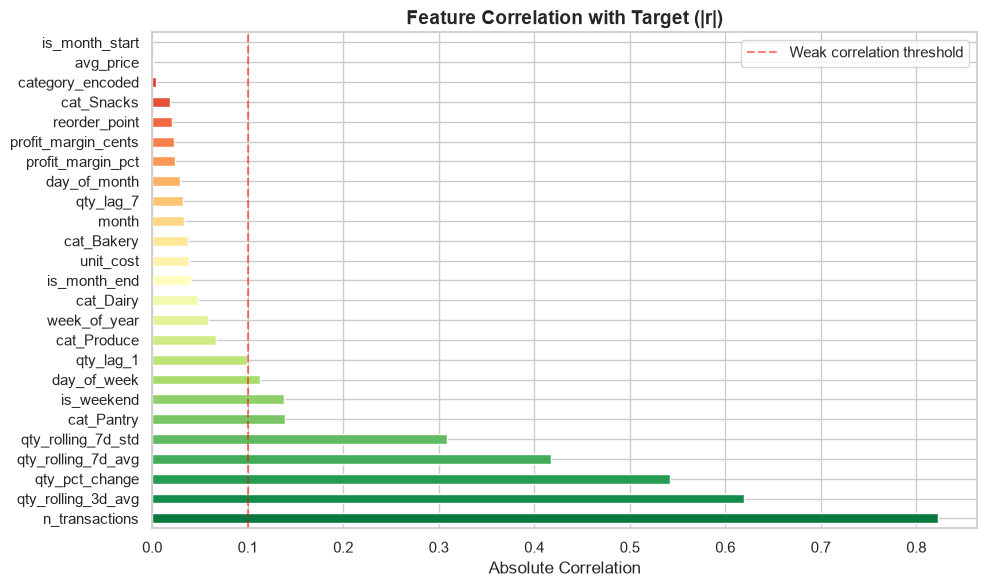

In [25]:
# === 11a: Correlation with target ===
print('=== Correlation with Target (total_qty) ===')
correlations = X_fs.corrwith(y_fs).abs().sort_values(ascending=False)
print(correlations.to_string())

# Visualize
plt.figure(figsize=(10, 6))
correlations.plot(kind='barh', color=sns.color_palette('RdYlGn_r', len(correlations)))
plt.title('Feature Correlation with Target (|r|)', fontweight='bold', fontsize=14)
plt.xlabel('Absolute Correlation')
plt.axvline(x=0.1, color='red', linestyle='--', alpha=0.5, label='Weak correlation threshold')
plt.legend()
plt.tight_layout()
plt.show()

=== Mutual Information Scores ===
qty_pct_change         1.213016
n_transactions         0.487747
qty_rolling_3d_avg     0.248365
qty_rolling_7d_std     0.116106
qty_rolling_7d_avg     0.095467
profit_margin_cents    0.056035
profit_margin_pct      0.050080
unit_cost              0.049784
avg_price              0.044258
is_weekend             0.042675
is_month_start         0.034641
month                  0.022357
cat_Bakery             0.019284
cat_Snacks             0.004461
cat_Dairy              0.002198
day_of_month           0.000160
category_encoded       0.000000
cat_Produce            0.000000
cat_Pantry             0.000000
reorder_point          0.000000
day_of_week            0.000000
is_month_end           0.000000
week_of_year           0.000000
qty_lag_7              0.000000
qty_lag_1              0.000000


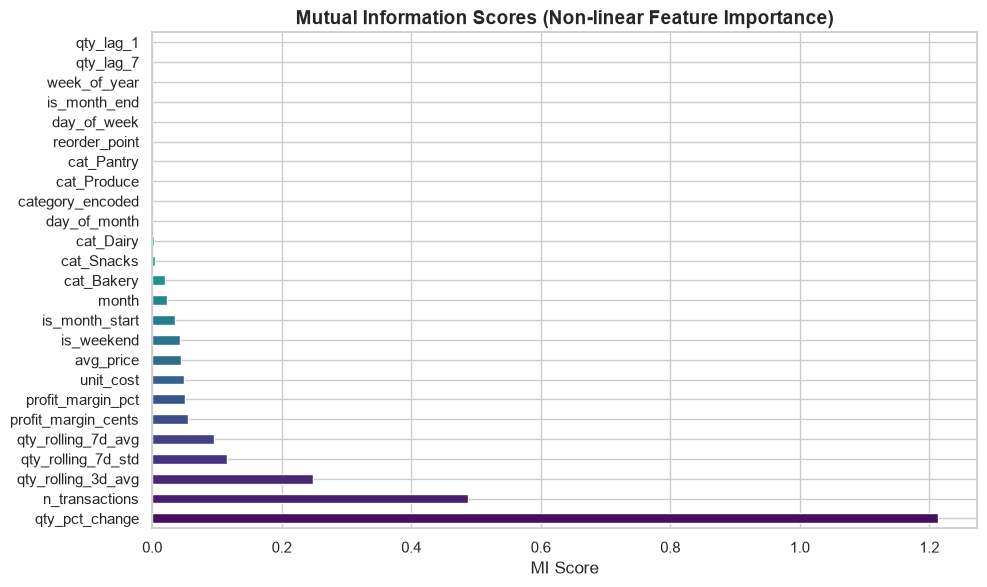

In [26]:
# === 11b: Mutual Information (captures non-linear relationships) ===
print('=== Mutual Information Scores ===')
mi_scores = mutual_info_regression(X_fs, y_fs, random_state=SEED)
mi_series = pd.Series(mi_scores, index=feature_cols).sort_values(ascending=False)

print(mi_series.to_string())

plt.figure(figsize=(10, 6))
mi_series.plot(kind='barh', color=sns.color_palette('viridis', len(mi_series)))
plt.title('Mutual Information Scores (Non-linear Feature Importance)', fontweight='bold', fontsize=14)
plt.xlabel('MI Score')
plt.tight_layout()
plt.show()

In [27]:
# === 11c: SelectKBest ===
print('=== SelectKBest (k=8, f_regression) ===')
k = min(8, len(feature_cols))
selector = SelectKBest(score_func=f_regression, k=k)
X_selected = selector.fit_transform(X_fs, y_fs)

selected_mask = selector.get_support()
selected_features = [f for f, s in zip(feature_cols, selected_mask) if s]

print(f'\nTop {k} features selected by SelectKBest:')
scores = pd.Series(selector.scores_, index=feature_cols).sort_values(ascending=False)
for i, (feat, score) in enumerate(scores.head(k).items(), 1):
    marker = '\u2705' if feat in selected_features else '  '
    print(f'  {marker} {i}. {feat}: F-score = {score:.2f}')

print(f'\n\u2705 Selected features: {selected_features}')

=== SelectKBest (k=8, f_regression) ===

Top 8 features selected by SelectKBest:
  ✅ 1. n_transactions: F-score = 3672.66
  ✅ 2. qty_rolling_3d_avg: F-score = 1092.92
  ✅ 3. qty_pct_change: F-score = 729.38
  ✅ 4. qty_rolling_7d_avg: F-score = 372.03
  ✅ 5. qty_rolling_7d_std: F-score = 184.89
  ✅ 6. cat_Pantry: F-score = 34.89
  ✅ 7. is_weekend: F-score = 34.23
  ✅ 8. day_of_week: F-score = 22.83

✅ Selected features: ['n_transactions', 'cat_Pantry', 'day_of_week', 'is_weekend', 'qty_rolling_3d_avg', 'qty_rolling_7d_avg', 'qty_rolling_7d_std', 'qty_pct_change']


---
## Section 12: Feature Extraction

Feature extraction transforms the original features into a new, reduced set of features that still captures the essential information.

1. **PCA (Principal Component Analysis)** — linear transformation to uncorrelated components
2. **Time-based feature extraction** — extract meaningful temporal patterns from timestamps

=== PCA Feature Extraction ===
Original features:   8
Extracted components: 6
Variance explained:  95.2%

Component Loadings (contribution of each feature to each PC):


,PC1,PC2,PC3,PC4,PC5,PC6
n_transactions,0.411,0.151,0.441,-0.037,-0.471,0.602
cat_Pantry,0.255,-0.097,-0.193,0.934,-0.105,-0.014
day_of_week,0.079,0.671,-0.198,0.030,0.081,-0.038
is_weekend,0.095,0.671,-0.190,-0.009,0.019,-0.046
qty_rolling_3d_avg,0.496,-0.086,-0.062,-0.251,-0.439,-0.497
qty_rolling_7d_avg,0.519,-0.140,-0.212,-0.128,0.166,-0.249
qty_rolling_7d_std,0.467,-0.127,-0.136,-0.124,0.628,0.412
qty_pct_change,0.134,0.155,0.791,0.178,0.380,-0.394


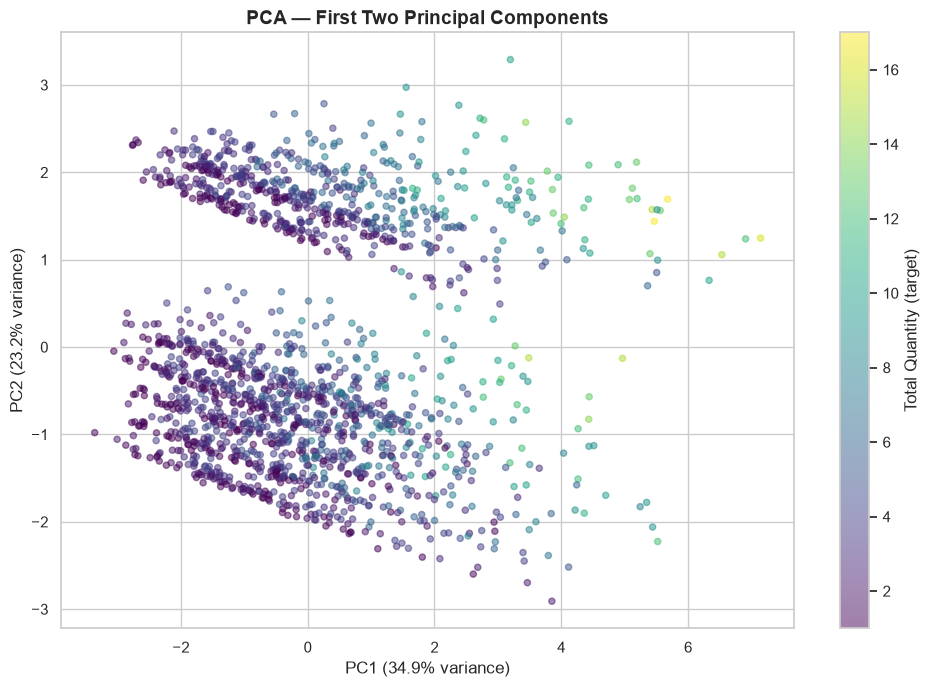

In [28]:
# ═══════════════════════════════════════════════════════════════
# Section 12: Feature Extraction
# ═══════════════════════════════════════════════════════════════

# === 12a: PCA Feature Extraction ===
print('=== PCA Feature Extraction ===')

# Use the selected features from Section 11
X_extract = X_fs[selected_features].copy()

# Standardize
scaler_extract = StandardScaler()
X_scaled = scaler_extract.fit_transform(X_extract)

# Fit PCA with n_components that explain 95% variance
pca_extract = PCA(n_components=0.95)  # keep enough components for 95% variance
X_pca_extracted = pca_extract.fit_transform(X_scaled)

print(f'Original features:   {X_extract.shape[1]}')
print(f'Extracted components: {X_pca_extracted.shape[1]}')
print(f'Variance explained:  {sum(pca_extract.explained_variance_ratio_)*100:.1f}%')

# Component loadings (how much each original feature contributes to each PC)
print('\nComponent Loadings (contribution of each feature to each PC):')
loadings = pd.DataFrame(
    pca_extract.components_.T,
    index=selected_features,
    columns=[f'PC{i+1}' for i in range(pca_extract.n_components_)]
)
display(loadings.round(3))

# Visualize PCA components
if X_pca_extracted.shape[1] >= 2:
    plt.figure(figsize=(10, 7))
    scatter = plt.scatter(X_pca_extracted[:, 0], X_pca_extracted[:, 1],
                         c=y_fs.values[:len(X_pca_extracted)], cmap='viridis', alpha=0.5, s=20)
    plt.colorbar(scatter, label='Total Quantity (target)')
    plt.xlabel(f'PC1 ({pca_extract.explained_variance_ratio_[0]*100:.1f}% variance)')
    plt.ylabel(f'PC2 ({pca_extract.explained_variance_ratio_[1]*100:.1f}% variance)')
    plt.title('PCA — First Two Principal Components', fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

=== Time-based Feature Extraction ===
Cyclical time features extracted:
  dow_sin, dow_cos    — Day of week (sin/cos encoded)
  month_sin, month_cos — Month (sin/cos encoded)
  dom_sin, dom_cos    — Day of month (sin/cos encoded)


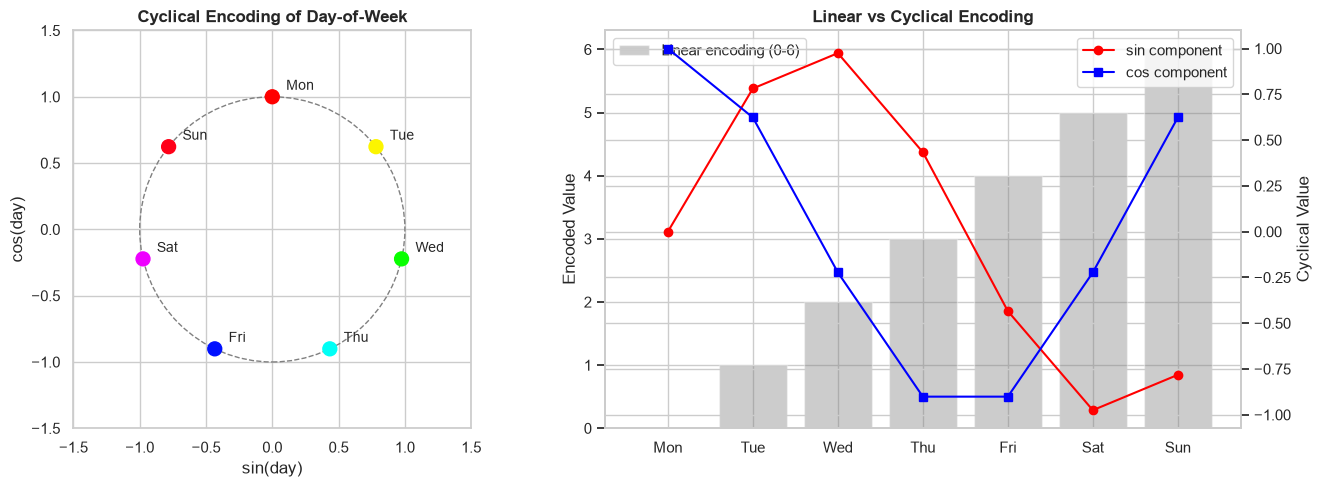

In [29]:
# === 12b: Time-based Feature Extraction ===
print('=== Time-based Feature Extraction ===')

# Cyclical encoding of time features (captures the circular nature of time)
# e.g., Day 7 (Sunday) is close to Day 1 (Monday), not far away

fe_df['dow_sin'] = np.sin(2 * np.pi * fe_df['day_of_week'] / 7)
fe_df['dow_cos'] = np.cos(2 * np.pi * fe_df['day_of_week'] / 7)
fe_df['month_sin'] = np.sin(2 * np.pi * fe_df['month'] / 12)
fe_df['month_cos'] = np.cos(2 * np.pi * fe_df['month'] / 12)
fe_df['dom_sin'] = np.sin(2 * np.pi * fe_df['day_of_month'] / 31)
fe_df['dom_cos'] = np.cos(2 * np.pi * fe_df['day_of_month'] / 31)

print('Cyclical time features extracted:')
print('  dow_sin, dow_cos    — Day of week (sin/cos encoded)')
print('  month_sin, month_cos — Month (sin/cos encoded)')
print('  dom_sin, dom_cos    — Day of month (sin/cos encoded)')

# Visualize cyclical encoding
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample = fe_df.drop_duplicates('day_of_week').sort_values('day_of_week')
axes[0].scatter(sample['dow_sin'], sample['dow_cos'], s=100, c=sample['day_of_week'], cmap='hsv', zorder=5)
for _, row in sample.iterrows():
    axes[0].annotate(day_labels[int(row['day_of_week'])], (row['dow_sin'], row['dow_cos']),
                     textcoords='offset points', xytext=(10, 5), fontsize=10)
circle = plt.Circle((0, 0), 1, fill=False, linestyle='--', color='gray')
axes[0].add_patch(circle)
axes[0].set_xlim(-1.5, 1.5)
axes[0].set_ylim(-1.5, 1.5)
axes[0].set_aspect('equal')
axes[0].set_title('Cyclical Encoding of Day-of-Week', fontweight='bold')
axes[0].set_xlabel('sin(day)')
axes[0].set_ylabel('cos(day)')

# Original vs cyclical comparison
axes[1].bar(day_labels, range(7), alpha=0.4, label='Linear encoding (0-6)', color='gray')
axes[1].set_ylabel('Encoded Value')
ax2 = axes[1].twinx()
ax2.plot(day_labels, sample.sort_values('day_of_week')['dow_sin'].values, 'ro-', label='sin component')
ax2.plot(day_labels, sample.sort_values('day_of_week')['dow_cos'].values, 'bs-', label='cos component')
ax2.set_ylabel('Cyclical Value')
axes[1].set_title('Linear vs Cyclical Encoding', fontweight='bold')
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

---
## Section 13: Preparation of Training and Testing Datasets

The final step is splitting the processed data into **training** and **testing** sets:

- **Training set** (~80%): Used to train the ML model
- **Testing set** (~20%): Used to evaluate model performance on unseen data

For time-series data (like sales forecasting), we also consider **temporal splitting** to avoid data leakage.

In [30]:
# ═══════════════════════════════════════════════════════════════
# Section 13: Train/Test Split — Preparing Final Datasets
# ═══════════════════════════════════════════════════════════════

print('=== Preparing Final ML-Ready Dataset ===')

# Use the feature-engineered DataFrame
final_df = fe_df.copy()

# Define target and features
target_col = 'total_qty'

# Select final feature set (using insights from feature selection)
final_features = [
    # Selected features from SelectKBest + domain knowledge
    'n_transactions', 'avg_price', 'unit_cost', 'reorder_point',
    'category_encoded',
    # Time features
    'day_of_week', 'is_weekend', 'month', 'week_of_year',
    'is_month_start', 'is_month_end',
    # Lag / rolling features
    'qty_lag_1', 'qty_rolling_3d_avg', 'qty_rolling_7d_avg', 'qty_rolling_7d_std',
    # Profit features
    'profit_margin_cents',
    # Category dummies
] + [c for c in final_df.columns if c.startswith('cat_')]

# Ensure all columns exist
final_features = [c for c in final_features if c in final_df.columns]

print(f'\nFinal feature set ({len(final_features)} features):')
for i, f in enumerate(final_features, 1):
    print(f'  {i:2d}. {f}')

# Drop rows with NaN (from lag features)
ml_df = final_df[final_features + [target_col, 'sale_date', 'product_id']].dropna()
print(f'\nDataset size after dropping NaN: {len(ml_df)} rows')

=== Preparing Final ML-Ready Dataset ===

Final feature set (21 features):
   1. n_transactions
   2. avg_price
   3. unit_cost
   4. reorder_point
   5. category_encoded
   6. day_of_week
   7. is_weekend
   8. month
   9. week_of_year
  10. is_month_start
  11. is_month_end
  12. qty_lag_1
  13. qty_rolling_3d_avg
  14. qty_rolling_7d_avg
  15. qty_rolling_7d_std
  16. profit_margin_cents
  17. cat_Bakery
  18. cat_Dairy
  19. cat_Pantry
  20. cat_Produce
  21. cat_Snacks

Dataset size after dropping NaN: 1999 rows


In [31]:
# === 13a: Random Train/Test Split (standard approach) ===
print('=== Method 1: Random 80/20 Split ===')

X = ml_df[final_features]
y = ml_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print(f'Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Testing set:  {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)')
print(f'Features:     {X_train.shape[1]}')
print(f'\nTarget distribution:')
print(f'  Train — mean: {y_train.mean():.2f}, std: {y_train.std():.2f}')
print(f'  Test  — mean: {y_test.mean():.2f}, std: {y_test.std():.2f}')

=== Method 1: Random 80/20 Split ===
Training set: 1599 samples (80.0%)
Testing set:  400 samples (20.0%)
Features:     21

Target distribution:
  Train — mean: 3.96, std: 2.56
  Test  — mean: 3.85, std: 2.59


In [32]:
# === 13b: Temporal Split (for time-series, avoids data leakage) ===
print('=== Method 2: Temporal Split (Last 20% of dates) ===')

ml_df_sorted = ml_df.sort_values('sale_date')
split_date = ml_df_sorted['sale_date'].quantile(0.8)

train_temporal = ml_df_sorted[ml_df_sorted['sale_date'] <= split_date]
test_temporal = ml_df_sorted[ml_df_sorted['sale_date'] > split_date]

X_train_temp = train_temporal[final_features]
y_train_temp = train_temporal[target_col]
X_test_temp = test_temporal[final_features]
y_test_temp = test_temporal[target_col]

print(f'Split date: {split_date}')
print(f'Training set: {len(train_temporal)} samples (dates ≤ {split_date.date()})')
print(f'Testing set:  {len(test_temporal)} samples (dates > {split_date.date()})')
print(f'\nTarget distribution:')
print(f'  Train — mean: {y_train_temp.mean():.2f}, std: {y_train_temp.std():.2f}')
print(f'  Test  — mean: {y_test_temp.mean():.2f}, std: {y_test_temp.std():.2f}')

=== Method 2: Temporal Split (Last 20% of dates) ===
Split date: 2026-08-21 00:00:00
Training set: 1602 samples (dates ≤ 2026-08-21)
Testing set:  397 samples (dates > 2026-08-21)

Target distribution:
  Train — mean: 3.95, std: 2.54
  Test  — mean: 3.89, std: 2.66


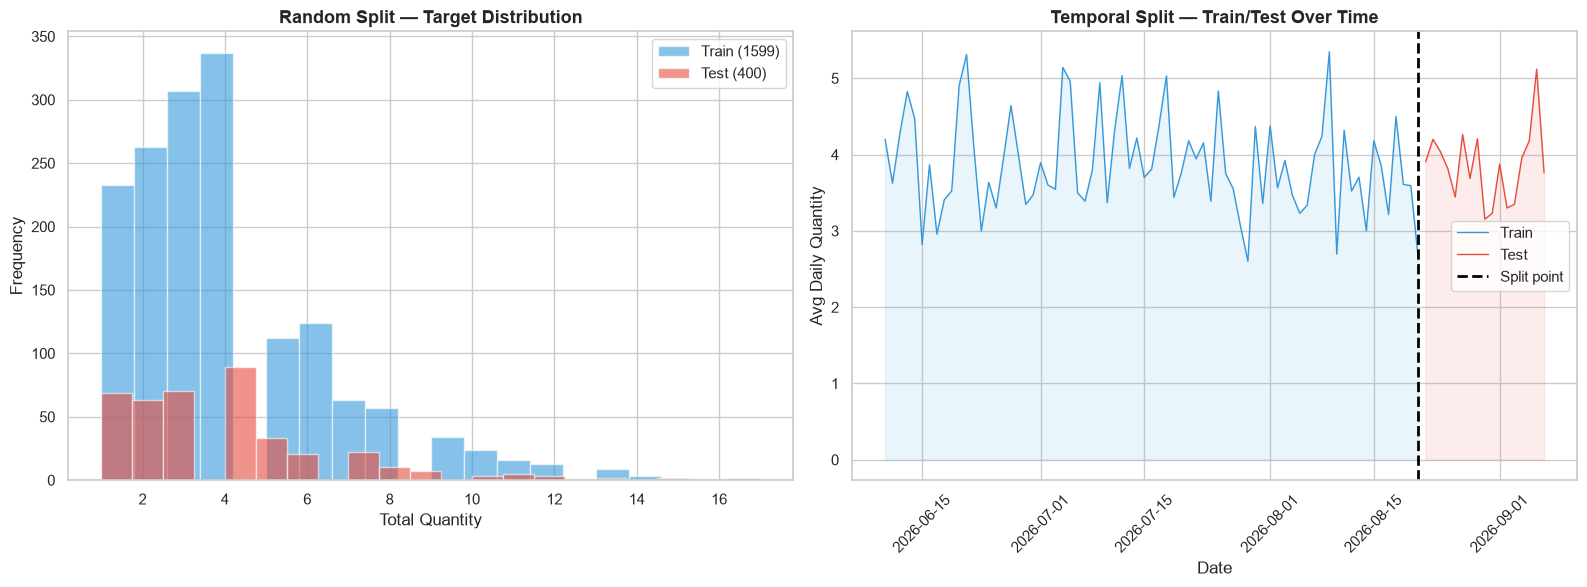

In [33]:
# Visualize the splits
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Random split target distribution
axes[0].hist(y_train, bins=20, alpha=0.6, label=f'Train ({len(y_train)})', color='#3498db')
axes[0].hist(y_test, bins=20, alpha=0.6, label=f'Test ({len(y_test)})', color='#e74c3c')
axes[0].set_title('Random Split — Target Distribution', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Total Quantity')
axes[0].set_ylabel('Frequency')
axes[0].legend()

# Temporal split visualization
train_daily = train_temporal.groupby('sale_date')[target_col].mean()
test_daily = test_temporal.groupby('sale_date')[target_col].mean()
axes[1].plot(train_daily.index, train_daily.values, color='#3498db', label='Train', linewidth=1)
axes[1].plot(test_daily.index, test_daily.values, color='#e74c3c', label='Test', linewidth=1)
axes[1].axvline(x=split_date, color='black', linestyle='--', linewidth=2, label='Split point')
axes[1].fill_between(train_daily.index, train_daily.values, alpha=0.1, color='#3498db')
axes[1].fill_between(test_daily.index, test_daily.values, alpha=0.1, color='#e74c3c')
axes[1].set_title('Temporal Split — Train/Test Over Time', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Avg Daily Quantity')
axes[1].legend()
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [34]:
# === Final Summary ===
print('=' * 70)
print('  GROCERYIQ — CE1 DATA PRE-PROCESSING PIPELINE SUMMARY')
print('=' * 70)
print(f'''
\u2705 Data Collection:        {len(products_df)} products, {len(transactions_df)} transactions,
                          {len(batches_df)} batches, {len(movements_df)} stock movements

\u2705 Data Cleaning:          Removed duplicates, fixed data types,
                          validated entries

\u2705 Missing Values:         Handled via median, mode, forward-fill,
                          and constant imputation strategies

\u2705 Data Integration:       Merged 4 DataFrames → unified analytics view
                          ({daily_product_sales.shape[0]} daily product-level records)

\u2705 Data Transformation:    Log transform (skewness reduction),
                          Label + One-Hot encoding

\u2705 Data Reduction:         PCA reduced {len(pca_features)} → {n_components_95} components
                          (95% variance retained)

\u2705 Feature Scaling:        Demonstrated Min-Max Normalization
                          and Z-Score Standardization

\u2705 Feature Engineering:    Created {len(new_cols)} new features
                          (time, revenue, rolling, interaction)

\u2705 Feature Selection:      SelectKBest identified top {k} features
                          using F-regression & Mutual Information

\u2705 Feature Extraction:     PCA components + cyclical time encoding

\u2705 Train/Test Split:       Random (80/20) and Temporal split prepared
                          Train: {X_train.shape[0]} | Test: {X_test.shape[0]}

FINAL DATASET: {X_train.shape[1]} features ready for ML model training
''')
print('=' * 70)

  GROCERYIQ — CE1 DATA PRE-PROCESSING PIPELINE SUMMARY

✅ Data Collection:        40 products, 1433 transactions,
                          120 batches, 2516 stock movements

✅ Data Cleaning:          Removed duplicates, fixed data types,
                          validated entries

✅ Missing Values:         Handled via median, mode, forward-fill,
                          and constant imputation strategies

✅ Data Integration:       Merged 4 DataFrames → unified analytics view
                          (2039 daily product-level records)

✅ Data Transformation:    Log transform (skewness reduction),
                          Label + One-Hot encoding

✅ Data Reduction:         PCA reduced 6 → 4 components
                          (95% variance retained)

✅ Feature Scaling:        Demonstrated Min-Max Normalization
                          and Z-Score Standardization

✅ Feature Engineering:    Created 20 new features
                          (time, revenue, rolling, interaction)

✅ Fe

In [35]:
# Display final processed datasets
print('=== Training Set (first 5 rows) ===')
display(X_train.head())

print('\n=== Training Target (first 5 values) ===')
print(y_train.head().values)

print(f'\n\u2705 Datasets ready for model training!')
print(f'   Next step: Use these datasets with Scikit-Learn, Prophet, or')
print(f'   other ML models for demand forecasting in GroceryIQ.')

=== Training Set (first 5 rows) ===


,n_transactions,avg_price,unit_cost,reorder_point,category_encoded,day_of_week,is_weekend,month,week_of_year,is_month_start,is_month_end,qty_lag_1,qty_rolling_3d_avg,qty_rolling_7d_avg,qty_rolling_7d_std,profit_margin_cents,cat_Bakery,cat_Dairy,cat_Pantry,cat_Produce,cat_Snacks
245,2,532.0,352,12,1,6,1,8,35,0,1,16.0,11.333333,7.857143,4.705620,180.0,False,True,False,False,False
829,1,658.0,102,14,1,2,0,6,26,0,0,6.0,3.333333,4.166667,3.710346,556.0,False,True,False,False,False
1861,4,106.0,192,28,3,5,1,8,31,1,0,1.0,6.333333,5.142857,3.848314,-86.0,False,False,False,True,False
1270,1,324.0,235,22,2,0,0,7,30,0,0,2.0,3.333333,3.285714,1.704336,89.0,False,False,True,False,False
1106,2,352.0,121,18,2,4,0,8,33,0,0,4.0,3.666667,4.000000,1.914854,231.0,False,False,True,False,False



=== Training Target (first 5 values) ===
[ 6  2 11  2  6]

✅ Datasets ready for model training!
   Next step: Use these datasets with Scikit-Learn, Prophet, or
   other ML models for demand forecasting in GroceryIQ.
